## 0. Imports

In [1]:
from __future__ import annotations

import logging
import warnings
from dataclasses import dataclass, field
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore")
logging.basicConfig(level=logging.INFO, format="%(levelname)s | %(message)s")
logger = logging.getLogger("agripak.cleaning")

sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 12})
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.3f}".format)

### 0.1 Paths, Logging, Schema & All Notebook Parameters

Single source of truth for the entire notebook:
- **Paths:** reads raw CSV from `data/raw/crop_data.csv` and saves cleaned / engineered outputs to `data/clean/`.
- **Logging:** `logger` (configured above) records every cleaning step via `CleaningLog`.
- **Schema & rules:** column groups, feature-engineering column sets, missing/binary mappings, domain ranges, leakage threshold, and CV parameters.

In [2]:
def resolve_data_path() -> Path:
    candidates = [
        Path("../../data/raw/crop_data.csv"),
        Path("../data/raw/crop_data.csv"),
        Path("data/raw/crop_data.csv"),
    ]
    for path in candidates:
        if path.exists():
            return path.resolve()
    raise FileNotFoundError("Could not locate data/raw/crop_data.csv from current working directory.")

DATA_PATH     = resolve_data_path()
PROJECT_ROOT  = DATA_PATH.parents[2]
CLEAN_DIR     = PROJECT_ROOT / "data" / "clean"
CLEAN_PATH    = CLEAN_DIR / "crop_data_clean.csv"
FEATURES_PATH = CLEAN_DIR / "crop_data_features.csv"

CATEGORICAL_COLS = ["region", "soil_type", "crop", "weather_condition"]
FLOAT_COLS       = ["rainfall_mm", "temperature_c"]
INT_COLS         = ["days_to_harvest"]
NUMERIC_COLS     = FLOAT_COLS + INT_COLS
FLAGS            = ["fertilizer_used", "irrigation_used"]
TARGET_COL       = "low_yield_risk"
BINARY_COLS      = FLAGS + [TARGET_COL]
binary_cols      = BINARY_COLS  # alias used in EDA cells

EXPECTED_COLS = [
    "region",
    "soil_type",
    "crop",
    "rainfall_mm",
    "temperature_c",
    "fertilizer_used",
    "irrigation_used",
    "weather_condition",
    "days_to_harvest",
    "low_yield_risk",
]

RAW_SIGNAL_COLS = ["rainfall_mm", "temperature_c", "fertilizer_used", "irrigation_used"]
ENG_COLS        = ["inputs_used", "rain_deficit", "deficit_x_noinputs", "rain_x_inputs"]
ALL_RAW_COLS    = RAW_SIGNAL_COLS + INT_COLS + CATEGORICAL_COLS
NO_RAIN_COLS    = ["temperature_c", "fertilizer_used", "irrigation_used"]

MISSING_TOKENS = {"", "na", "n/a", "null", "none", "nan", "?", "-"}
BINARY_MAP = {
    "1": 1, "0": 0, "1.0": 1, "0.0": 0,
    "yes": 1, "no": 0, "true": 1, "false": 0, "y": 1, "n": 0,
}
VALID_RANGES = {
    "rainfall_mm": (0, 5000),
    "temperature_c": (-10, 60),
    "days_to_harvest": (1, 400),
}

# --- Thresholds & modeling parameters ---
LEAK_THRESH   = 0.90
RAIN_FLOOR_MM = 800.0
RANDOM_STATE  = 42
N_SPLITS      = 5

print(f"Raw data:      {DATA_PATH}")
print(f"Clean output:  {CLEAN_PATH}")
print(f"Features out:  {FEATURES_PATH}")

Raw data:      /home/death_note/Projects/AgriPak/data/raw/crop_data.csv
Clean output:  /home/death_note/Projects/AgriPak/data/clean/crop_data_clean.csv
Features out:  /home/death_note/Projects/AgriPak/data/clean/crop_data_features.csv


## 1. Load Raw Dataset

In [3]:
raw_df = pd.read_csv(DATA_PATH)
data   = raw_df.copy()
BASE   = data[TARGET_COL].mean()
MIN_N  = max(20, int(0.01 * len(data)))
display(data.head())

,region,soil_type,crop,rainfall_mm,temperature_c,fertilizer_used,irrigation_used,weather_condition,days_to_harvest,low_yield_risk
0,West,Silt,Cotton,714.850,23.880,0,0,Sunny,120,1
1,North,Chalky,Cotton,860.600,23.070,0,0,Rainy,78,0
2,North,Sandy,Barley,802.080,24.020,1,1,Rainy,140,0
3,West,Chalky,Cotton,203.620,16.900,0,1,Sunny,96,1
4,East,Silt,Rice,510.530,18.400,0,1,Cloudy,65,1


### 1.1 Cleaning Audit Logger

`CleaningLog` records every cleaning decision and affected row count so we can reuse it in Section 3 and export a Markdown audit table.

In [4]:
# used for helping it with the markdown
@dataclass
class CleaningLog:
    entries: list[dict] = field(default_factory=list)

    def add(self, step: str, issue: str, action: str, rows_affected: int = 0) -> None:
        self.entries.append(
            {"step": step, "issue": issue, "action": action, "rows_affected": rows_affected}
        )
        logger.info("%s | %s -> %s (%d affected)", step, issue, action, rows_affected)

    def to_dataframe(self) -> pd.DataFrame:
        return pd.DataFrame(self.entries)

    def to_markdown(self) -> str:
        lines = ["| Step | Issue found | Decision | Rows affected |",
                 "|------|-------------|----------|---------------|"]
        for e in self.entries:
            lines.append(f"| {e['step']} | {e['issue']} | {e['action']} | {e['rows_affected']} |")
        return "\n".join(lines)

### 1.2 Dataset Structure, Summary Statistics & Target Balance

Check column dtypes, non-null counts, summary statistics, dimensions, and class balance for `low_yield_risk`.

In [5]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   region             50000 non-null  str    
 1   soil_type          50000 non-null  str    
 2   crop               50000 non-null  str    
 3   rainfall_mm        50000 non-null  float64
 4   temperature_c      50000 non-null  float64
 5   fertilizer_used    50000 non-null  int64  
 6   irrigation_used    50000 non-null  int64  
 7   weather_condition  50000 non-null  str    
 8   days_to_harvest    50000 non-null  int64  
 9   low_yield_risk     50000 non-null  int64  
dtypes: float64(2), int64(4), str(4)
memory usage: 3.8 MB


In [6]:
display(data.describe().T)

,count,mean,std,min,25%,50%,75%,max
rainfall_mm,50000.000,550.873,259.775,100.010,325.923,550.285,774.422,999.980
temperature_c,50000.000,27.428,7.232,15.000,21.150,27.420,33.670,40.000
fertilizer_used,50000.000,0.499,0.500,0.000,0.000,0.000,1.000,1.000
irrigation_used,50000.000,0.499,0.500,0.000,0.000,0.000,1.000,1.000
days_to_harvest,50000.000,104.606,25.891,60.000,82.000,105.000,127.000,149.000
low_yield_risk,50000.000,0.350,0.477,0.000,0.000,0.000,1.000,1.000


In [7]:
height, width = data.shape
print(f'{height:,} rows x {width} cols | baseline risk {BASE:.1%} | MIN_N {MIN_N}')

50,000 rows x 10 cols | baseline risk 35.0% | MIN_N 500


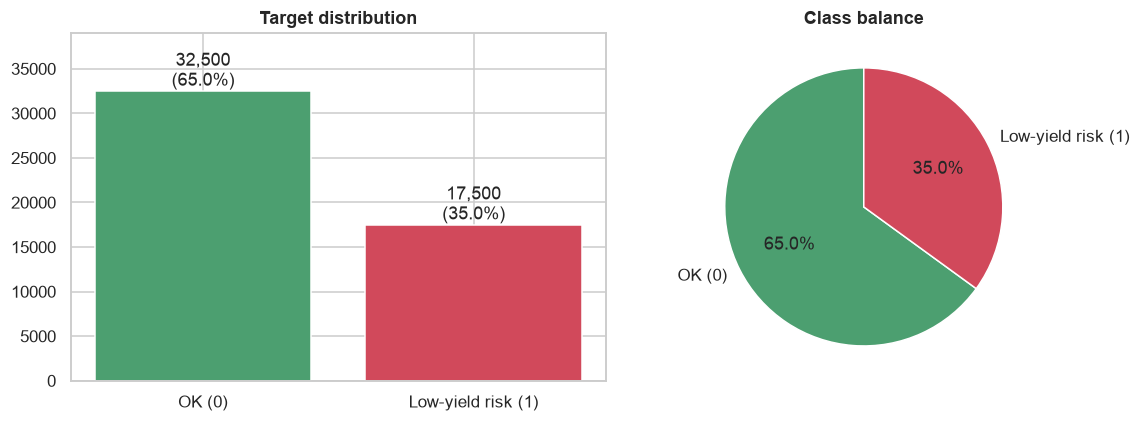

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

counts = data[TARGET_COL].value_counts().sort_index()
labels = ["OK (0)", "Low-yield risk (1)"]

axes[0].bar(labels, counts.values, color=["#4C9F70", "#D1495B"])

for i, v in enumerate(counts.values):
    axes[0].text(i, v, f"{v:,}\n({v/height:.1%})", ha="center", va="bottom")
axes[0].set_title("Target distribution"); axes[0].set_ylim(0, counts.max() * 1.2)

axes[1].pie(counts.values, labels=labels, autopct="%1.1f%%",
            colors=["#4C9F70", "#D1495B"], startangle=90)
axes[1].set_title("Class balance")

plt.tight_layout(); plt.show()

**What the output says:**
- **Shape & completeness:** `50,000` rows × `10` columns (`2` float, `4` int, `4` string), `0` nulls, `3.8 MB` in memory.
- **Target balance:** Exact `65.0%` OK (`32,500`) vs `35.0%` low-yield risk (`17,500`) — moderate imbalance, no extreme rarity.
- **Binary inputs:** `fertilizer_used` and `irrigation_used` are ~50/50 split (`mean ≈ 0.499`).

## 2. Data Quality Audit

### 2.1 Nulls, Cardinality, Exact Duplicates & Text Hygiene

Verify missing values, unique counts per column, duplicate rows, leading/trailing whitespace, and string placeholder tokens (`na`, `null`, `?`, etc.).

In [9]:
audit_summary = pd.DataFrame(
    {
        "dtype": data.dtypes.astype(str),
        "null_count": data.isna().sum(),
        "null_pct": (data.isna().mean() * 100).round(3),
        "nunique": data.nunique(dropna=False),
    }
)

audit_summary

,dtype,null_count,null_pct,nunique
region,str,0,0.000,4
soil_type,str,0,0.000,6
crop,str,0,0.000,6
rainfall_mm,float64,0,0.000,38405
temperature_c,float64,0,0.000,2501
fertilizer_used,int64,0,0.000,2
irrigation_used,int64,0,0.000,2
weather_condition,str,0,0.000,3
days_to_harvest,int64,0,0.000,90
low_yield_risk,int64,0,0.000,2


### Duplicates

In [10]:
print(f"Exact duplicate rows: {data.duplicated().sum()}")

Exact duplicate rows: 0


In [11]:
text = pd.read_csv(DATA_PATH, dtype=str, keep_default_na=False)

text_checks = []
for col in text.columns:
    series = text[col]
    stripped = series.str.strip()
    text_checks.append(
        {
            "column": col,
            "leading_or_trailing_ws": int((series != stripped).sum()),
            "placeholder_or_empty": int(stripped.str.lower().isin(MISSING_TOKENS).sum()),
        }
    )

pd.DataFrame(text_checks)

,column,leading_or_trailing_ws,placeholder_or_empty
0,region,0,0
1,soil_type,0,0
2,crop,0,0
3,rainfall_mm,0,0
4,temperature_c,0,0
5,fertilizer_used,0,0
6,irrigation_used,0,0
7,weather_condition,0,0
8,days_to_harvest,0,0
9,low_yield_risk,0,0


**What the output says:**
- **Zero data defects found:** `0` nulls, `0` exact duplicate rows, `0` whitespace issues, and `0` placeholder tokens across all 10 columns.
- **Cardinality matches domain:** `4` regions, `6` soil types, `6` crops, `3` weather conditions, `90` distinct harvest days, and binary `0/1` flags.

### 2.2 Numeric Distributions, Boxplots & Shape Metrics

Inspect histograms, boxplots, skewness, and kurtosis for `rainfall_mm`, `temperature_c`, and `days_to_harvest`.

In [12]:
display(data.describe(include="number").T)

,count,mean,std,min,25%,50%,75%,max
rainfall_mm,50000.000,550.873,259.775,100.010,325.923,550.285,774.422,999.980
temperature_c,50000.000,27.428,7.232,15.000,21.150,27.420,33.670,40.000
fertilizer_used,50000.000,0.499,0.500,0.000,0.000,0.000,1.000,1.000
irrigation_used,50000.000,0.499,0.500,0.000,0.000,0.000,1.000,1.000
days_to_harvest,50000.000,104.606,25.891,60.000,82.000,105.000,127.000,149.000
low_yield_risk,50000.000,0.350,0.477,0.000,0.000,0.000,1.000,1.000


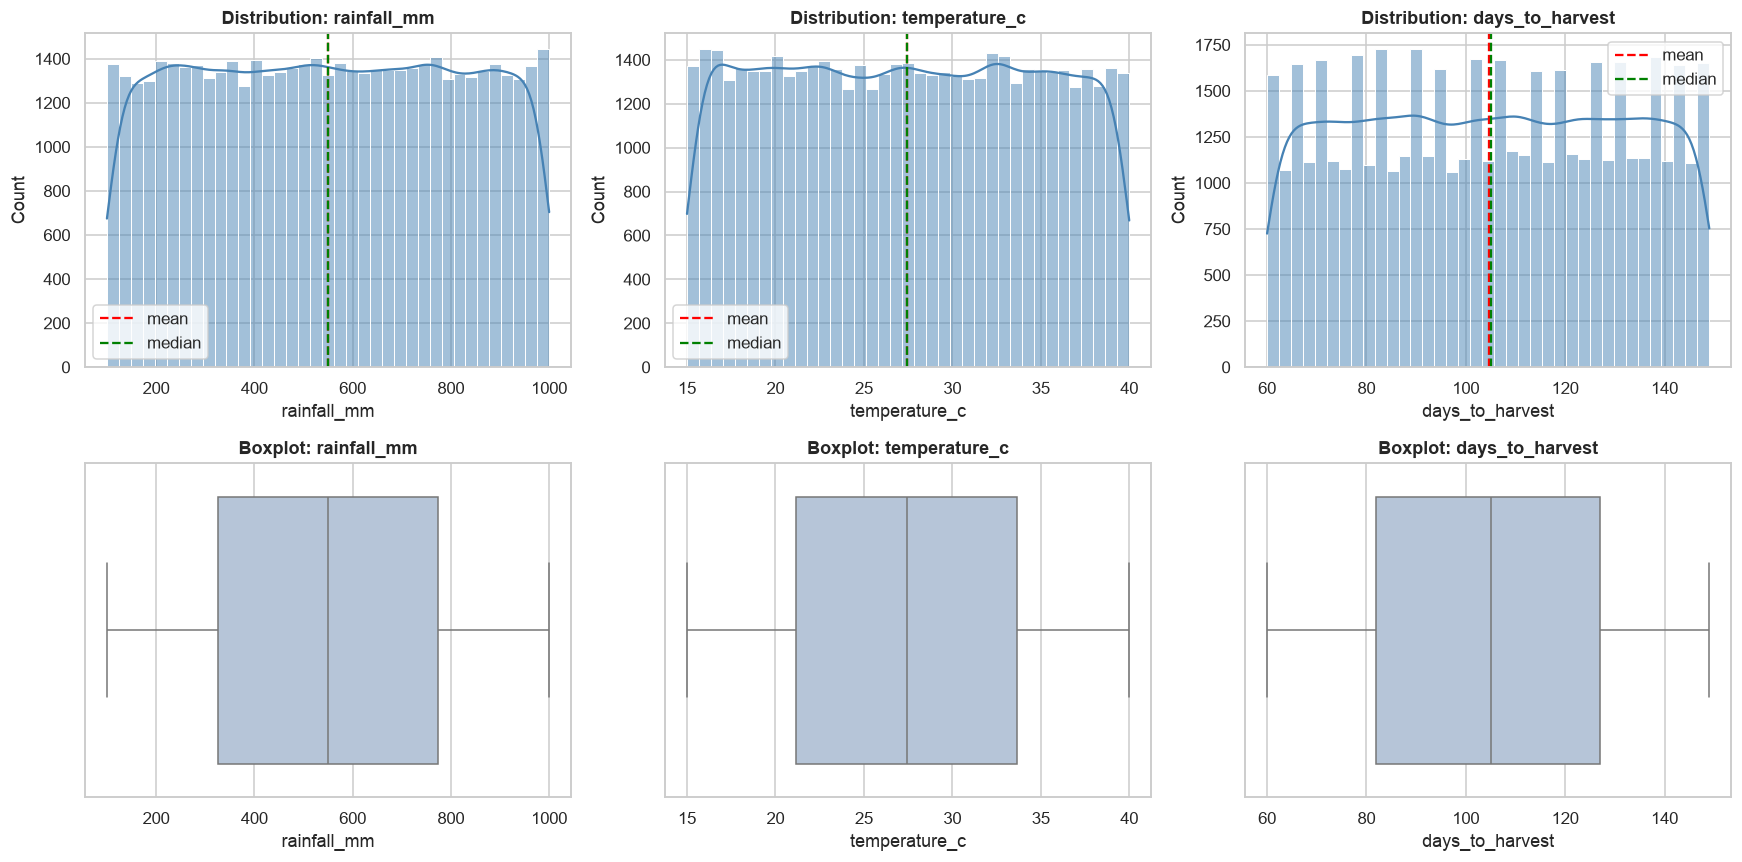

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))

for i, col in enumerate(NUMERIC_COLS):
    sns.histplot(data[col], kde=True, ax=axes[0, i], color="steelblue")
    axes[0, i].axvline(data[col].mean(), color="red", ls="--", label="mean")
    axes[0, i].axvline(data[col].median(), color="green", ls="--", label="median")
    axes[0, i].legend(); axes[0, i].set_title(f"Distribution: {col}")
    sns.boxplot(x=data[col], ax=axes[1, i], color="lightsteelblue")
    axes[1, i].set_title(f"Boxplot: {col}")
plt.tight_layout(); plt.show()

In [14]:
shape = pd.DataFrame({"skew": data[NUMERIC_COLS].apply(stats.skew),
                      "kurtosis": data[NUMERIC_COLS].apply(stats.kurtosis),
                      "n_unique": data[NUMERIC_COLS].nunique()})
display(shape)

,skew,kurtosis,n_unique
rainfall_mm,-0.000,-1.196,38405
temperature_c,0.007,-1.205,2501
days_to_harvest,-0.001,-1.197,90


**What the output says:**
- All three numeric features (`rainfall_mm`: `100–1000 mm`, `temperature_c`: `15–40 °C`, `days_to_harvest`: `60–149 days`) have **`skew ≈ 0`** and **`kurtosis ≈ -1.20`**.
- Kurtosis of `-1.2` is the exact signature of a **uniform distribution** with no outliers or heavy tails.

### 2.3 Categorical & Binary Feature Distributions

Check category balance across `region`, `soil_type`, `crop`, `weather_condition`, `fertilizer_used`, and `irrigation_used`.

In [15]:
categorical_cols = ["region", "soil_type", "crop", "weather_condition"]
for col in categorical_cols:
    print(f"\n--- {col} ---")
    print(data[col].value_counts(dropna=False))


--- region ---
region
South    12616
West     12560
North    12487
East     12337
Name: count, dtype: int64

--- soil_type ---
soil_type
Clay      8451
Loam      8415
Peaty     8399
Chalky    8351
Sandy     8212
Silt      8172
Name: count, dtype: int64

--- crop ---
crop
Cotton     8438
Soybean    8386
Rice       8336
Wheat      8335
Barley     8310
Maize      8195
Name: count, dtype: int64

--- weather_condition ---
weather_condition
Rainy     16703
Sunny     16694
Cloudy    16603
Name: count, dtype: int64


INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


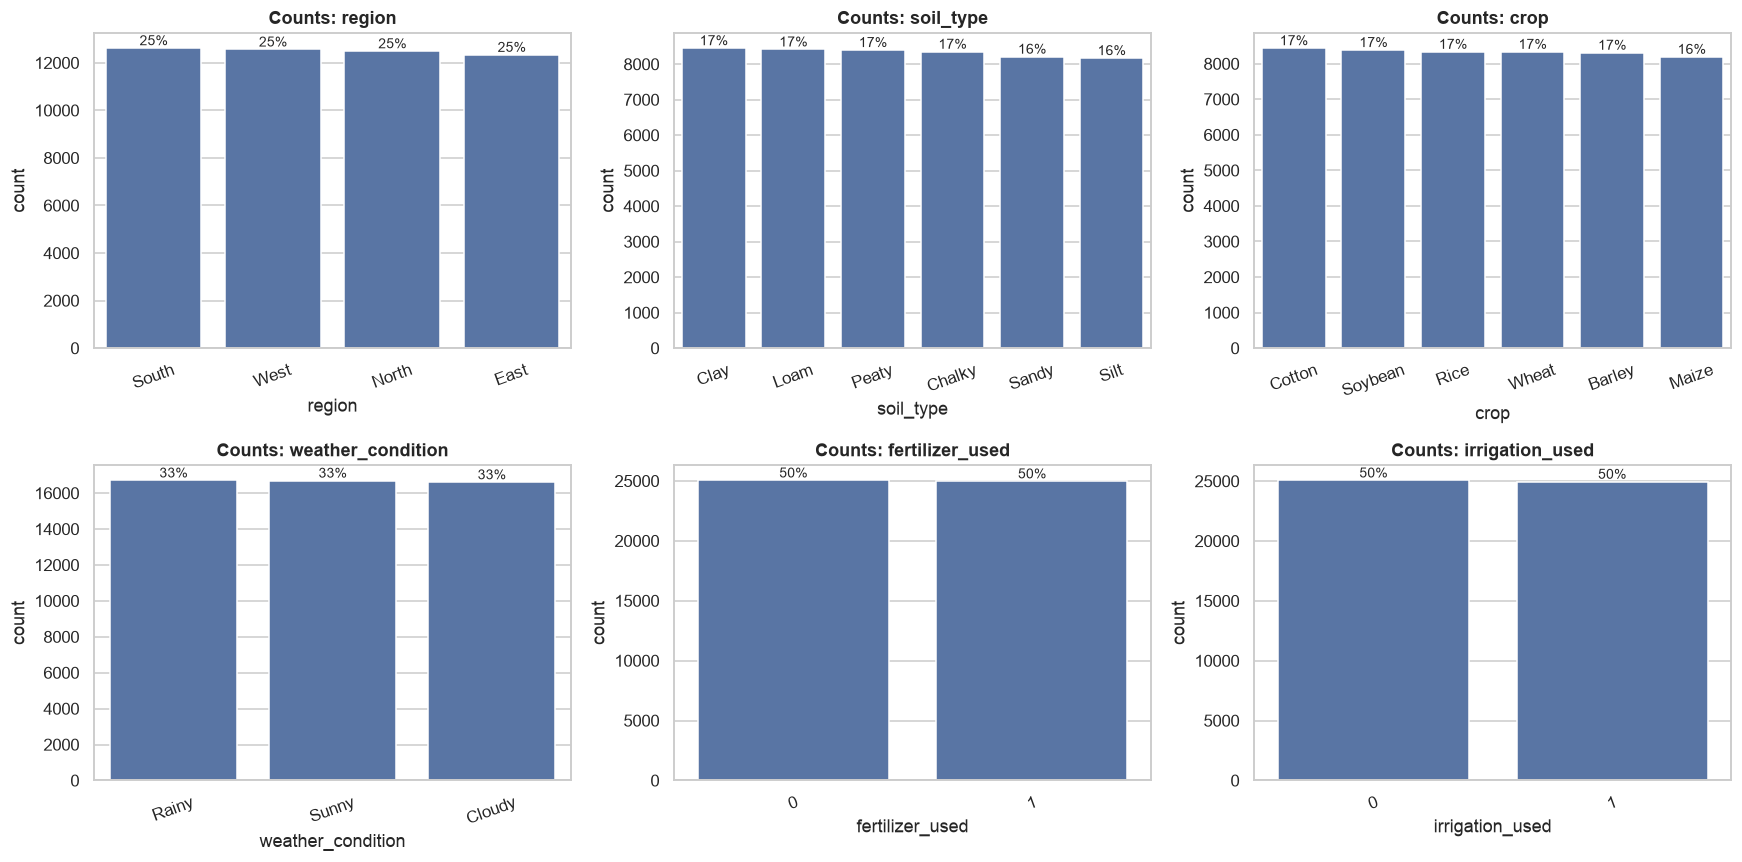

In [16]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))

for ax, col in zip(axes.ravel(), CATEGORICAL_COLS + FLAGS):
    order = data[col].value_counts().index
    sns.countplot(data=data, x=col, order=order, ax=ax)
    for p in ax.patches:
        ax.annotate(f"{p.get_height()/height:.0%}", (p.get_x() + p.get_width()/2, p.get_height()),
                    ha="center", va="bottom", fontsize=9)
    ax.set_title(f"Counts: {col}"); ax.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()

In [17]:
for col in binary_cols:
    counts = data[col].value_counts(dropna=False).sort_index()
    pct = (data[col].value_counts(normalize=True).sort_index() * 100).round(2)
    print(f"\n--- {col} ---")
    print(pd.DataFrame({"count": counts, "pct": pct}))


--- fertilizer_used ---
                 count    pct
fertilizer_used              
0                25037 50.070
1                24963 49.930

--- irrigation_used ---
                 count    pct
irrigation_used              
0                25054 50.110
1                24946 49.890

--- low_yield_risk ---
                count    pct
low_yield_risk              
0               32500 65.000
1               17500 35.000


INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


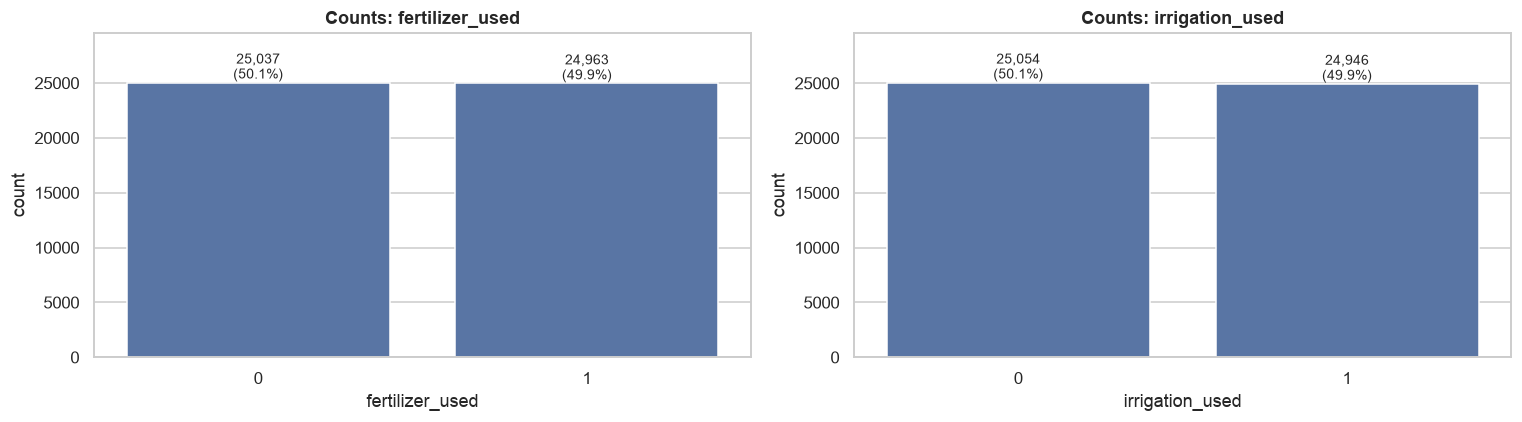

In [18]:
fig, axes = plt.subplots(1, len(FLAGS), figsize=(14, 4))

for ax, col in zip(axes.ravel(), FLAGS):
    order = data[col].value_counts().sort_index().index
    sns.countplot(data=data, x=col, order=order, ax=ax)
    for p in ax.patches:
        h = p.get_height()
        ax.annotate(
            f"{int(h):,}\n({h/height:.1%})",
            (p.get_x() + p.get_width() / 2, h),
            ha="center",
            va="bottom",
            fontsize=9,
        )
    ax.set_title(f"Counts: {col}")
    ax.margins(y=0.18)

plt.tight_layout()
plt.show()

**What the output says:**
- Every categorical and binary predictor is **uniformly balanced**: ~25% per region, ~16.7% per soil/crop, ~33.3% per weather condition, and ~50/50 for `fertilizer_used` and `irrigation_used`.

### 2.4 Low-Yield Risk Rate by Categorical & Binary Features

Compare target risk rate across every level of each categorical and binary feature against the `35.0%` baseline.

INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


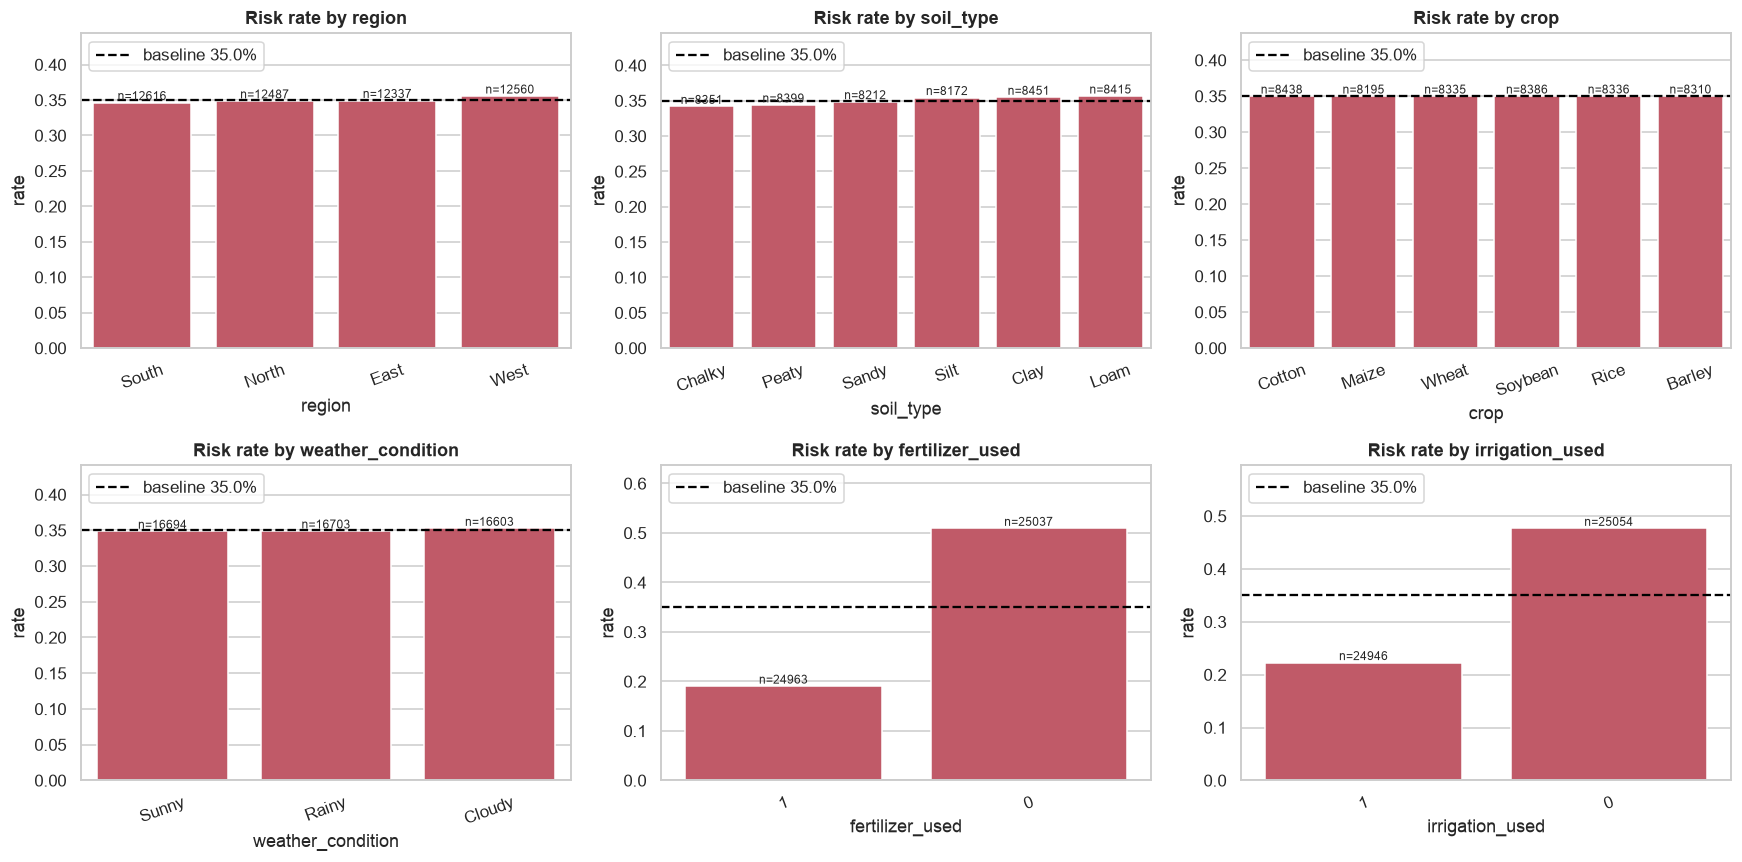

In [19]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))

for ax, col in zip(axes.ravel(), CATEGORICAL_COLS + FLAGS):
    g = (data.groupby(col)[TARGET_COL].agg(rate="mean", n="size")
           .reset_index().sort_values("rate"))
    g[col] = g[col].astype(str
                          )
    sns.barplot(data=g, x=col, y="rate", order=g[col], ax=ax, color="#D1495B")
    ax.axhline(BASE, color="black", ls="--", label=f"baseline {BASE:.1%}")
    
    for p, n in zip(ax.patches, g["n"]):
        ax.annotate(f"n={n}", (p.get_x() + p.get_width()/2, p.get_height()),
                    ha="center", va="bottom", fontsize=8)
    
    ax.set_ylim(0, min(1, g["rate"].max() * 1.25)); ax.set_title(f"Risk rate by {col}")
    
    ax.legend(loc="upper left"); ax.tick_params(axis="x", rotation=20)

plt.tight_layout(); plt.show()

**What the output says:**
- **`region`, `soil_type`, `crop`, and `weather_condition` are flat** at the `35.0%` baseline — none separates risk on its own.
- **`fertilizer_used` and `irrigation_used` are strong signals:** risk drops sharply when either input is applied (~51% → ~19% for fertilizer; ~48% → ~22% for irrigation).

### 2.5 Numeric Distributions by Risk Class & Mann-Whitney U Tests

Compare `OK (0)` vs `Risk (1)` densities, violins, medians, and rank-biserial effect sizes.

INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO | Using ca

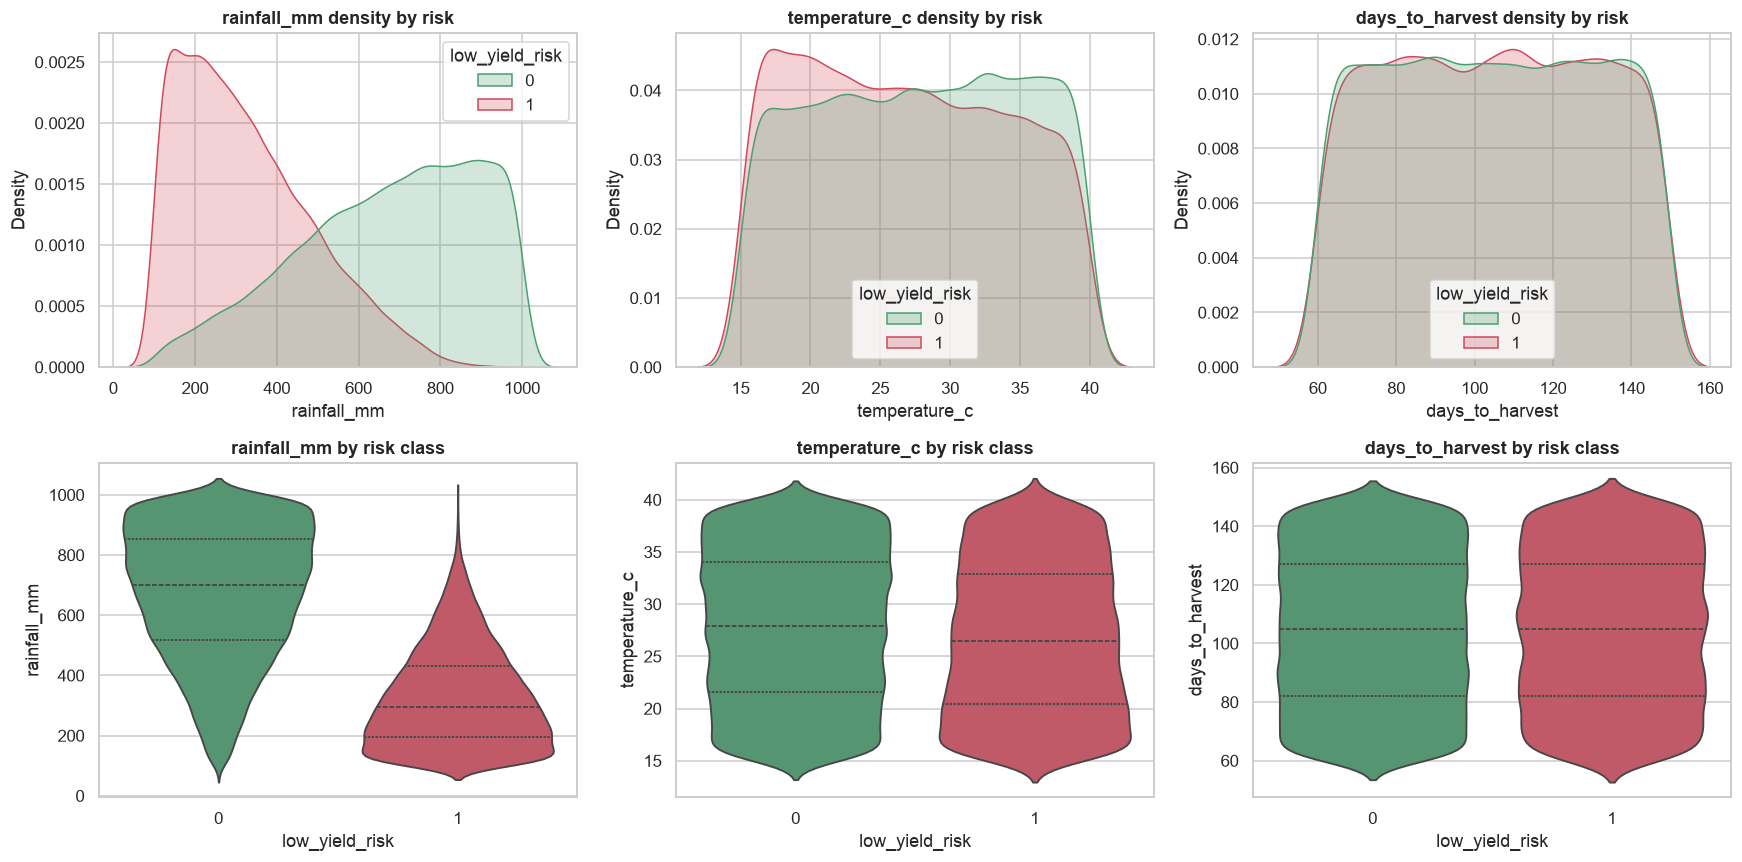

In [20]:
from scipy import stats

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
rows = []

for i, col in enumerate(NUMERIC_COLS):
    sns.kdeplot(data=data, x=col, hue=TARGET_COL, fill=True, common_norm=False,
                palette={0: "#4C9F70", 1: "#D1495B"}, ax=axes[0, i])
    axes[0, i].set_title(f"{col} density by risk")

    sns.violinplot(data=data, x=TARGET_COL, y=col, hue=TARGET_COL, legend=False,
               order=[0, 1], hue_order=[0, 1],
               palette=["#4C9F70", "#D1495B"],
               inner="quartile", ax=axes[1, i])
    
    axes[1, i].set_title(f"{col} by risk class")

    a = data.loc[data[TARGET_COL] == 1, col]
    b = data.loc[data[TARGET_COL] == 0, col]
    u, p = stats.mannwhitneyu(a, b)
    
    rows.append({"feature": col, "median_risk=1": a.median(), "median_risk=0": b.median(),
                 "p_value": p, "rank_biserial": 2 * u / (len(a) * len(b)) - 1})

plt.tight_layout(); plt.show()

In [21]:
mw = pd.DataFrame(rows).set_index("feature")
display(mw)

,median_risk=1,median_risk=0,p_value,rank_biserial
feature,,,,
rainfall_mm,295.330,700.630,0.000,-0.770
temperature_c,26.440,27.930,0.000,-0.083
days_to_harvest,105.000,105.000,0.554,0.003


**What the output says:**
- **`rainfall_mm` dominates:** median `295.3 mm` (risk=1) vs `700.6 mm` (risk=0), rank-biserial **`-0.770`** (`p ≈ 0`). Risk peaks at `150–300 mm` and nearly disappears above `800 mm`.
- **`temperature_c` is a weak monotone effect:** median `26.4 °C` (risk=1) vs `27.9 °C` (risk=0), rank-biserial **`-0.083`** (`p ≈ 0`, hotter → slightly lower risk).
- **`days_to_harvest` has zero signal:** median `105` in both classes, rank-biserial `0.003` (`p = 0.554`).

### 2.6 Spearman Correlation & Decile Risk Curves

Measure monotonic associations with `low_yield_risk` and plot risk rate with 95% CIs across numeric deciles.

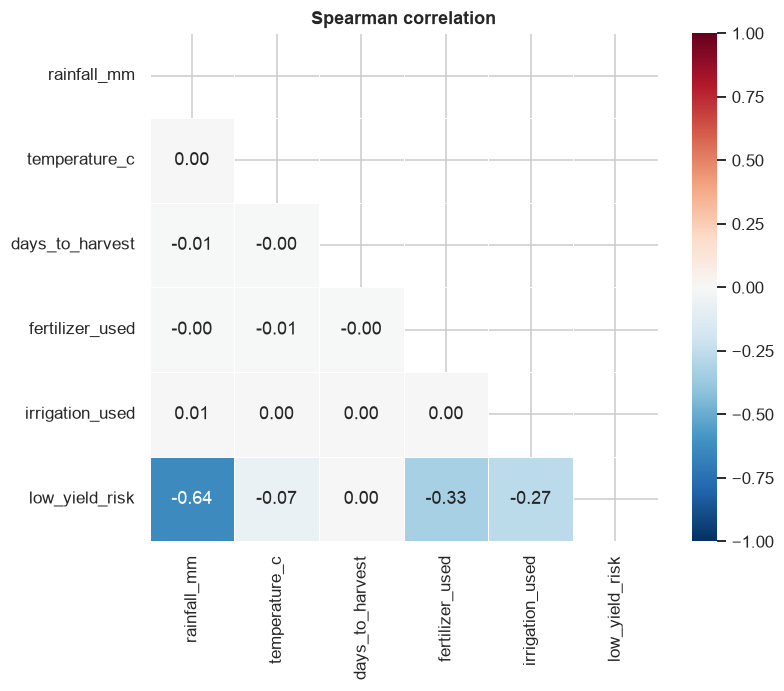

In [22]:
corr_cols = NUMERIC_COLS + FLAGS + [TARGET_COL]

corr = data[corr_cols].corr(method="spearman")

mask = np.triu(np.ones_like(corr, dtype=bool))

plt.figure(figsize=(8, 6))

sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            linewidths=0.5, square=True)
plt.title("Spearman correlation"); plt.show()

In [23]:
display(corr[TARGET_COL].drop(TARGET_COL).sort_values(key=abs, ascending=False).to_frame("corr_with_risk"))

,corr_with_risk
rainfall_mm,-0.636
fertilizer_used,-0.334
irrigation_used,-0.266
temperature_c,-0.069
days_to_harvest,0.003


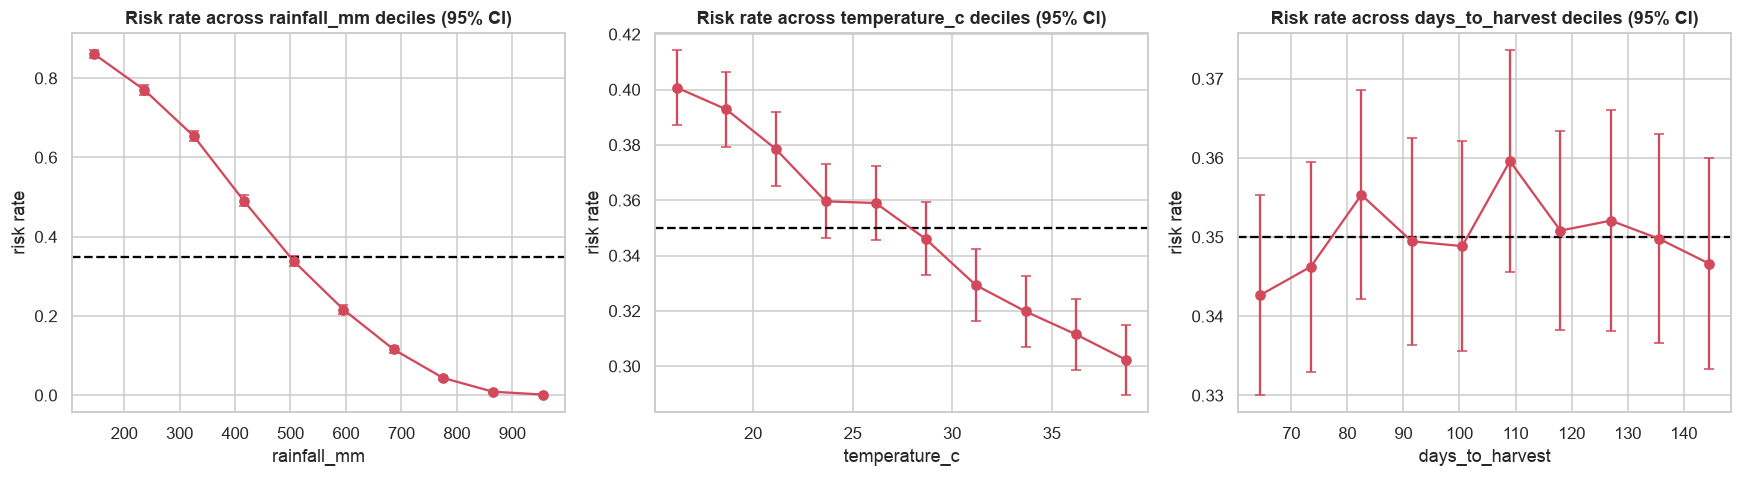

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for ax, col in zip(axes, NUMERIC_COLS):
    
    bins = pd.qcut(data[col], 10, duplicates="drop")
    
    g = data.groupby(bins, observed=True)[TARGET_COL].agg(["mean", "count"])
    
    se = np.sqrt(g["mean"] * (1 - g["mean"]) / g["count"])
    x = [iv.mid for iv in g.index]
    
    ax.errorbar(x, g["mean"], yerr=1.96 * se, marker="o", capsize=3, color="#D1495B")
    ax.axhline(BASE, color="black", ls="--")
    ax.set_title(f"Risk rate across {col} deciles (95% CI)")
    ax.set_xlabel(col); ax.set_ylabel("risk rate")

plt.tight_layout(); plt.show()

**What the output says:**
- **Strength ranking (`|Spearman|`):** `rainfall_mm (-0.636)` > `fertilizer_used (-0.334)` > `irrigation_used (-0.266)` > `temperature_c (-0.069)` > `days_to_harvest (0.003)`.
- **Threshold/floor effect in rainfall:** risk falls almost linearly from ~86% (`150 mm`) to ~0% above **`800 mm`**, directly motivating a hinge feature (`rain_deficit = max(0, 800 - rainfall_mm)`).
- `temperature_c` slopes gently downward (`40% → 30%`); `days_to_harvest` fluctuates randomly around `35%`.

### 2.7 Pairwise Heatmaps, Multi-Feature Combinations & Split Replication

Scan 2-way and 3-way feature combinations (`n >= 500`) for high-risk, protective, and synergistic interactions, then test replication on a 50/50 split.

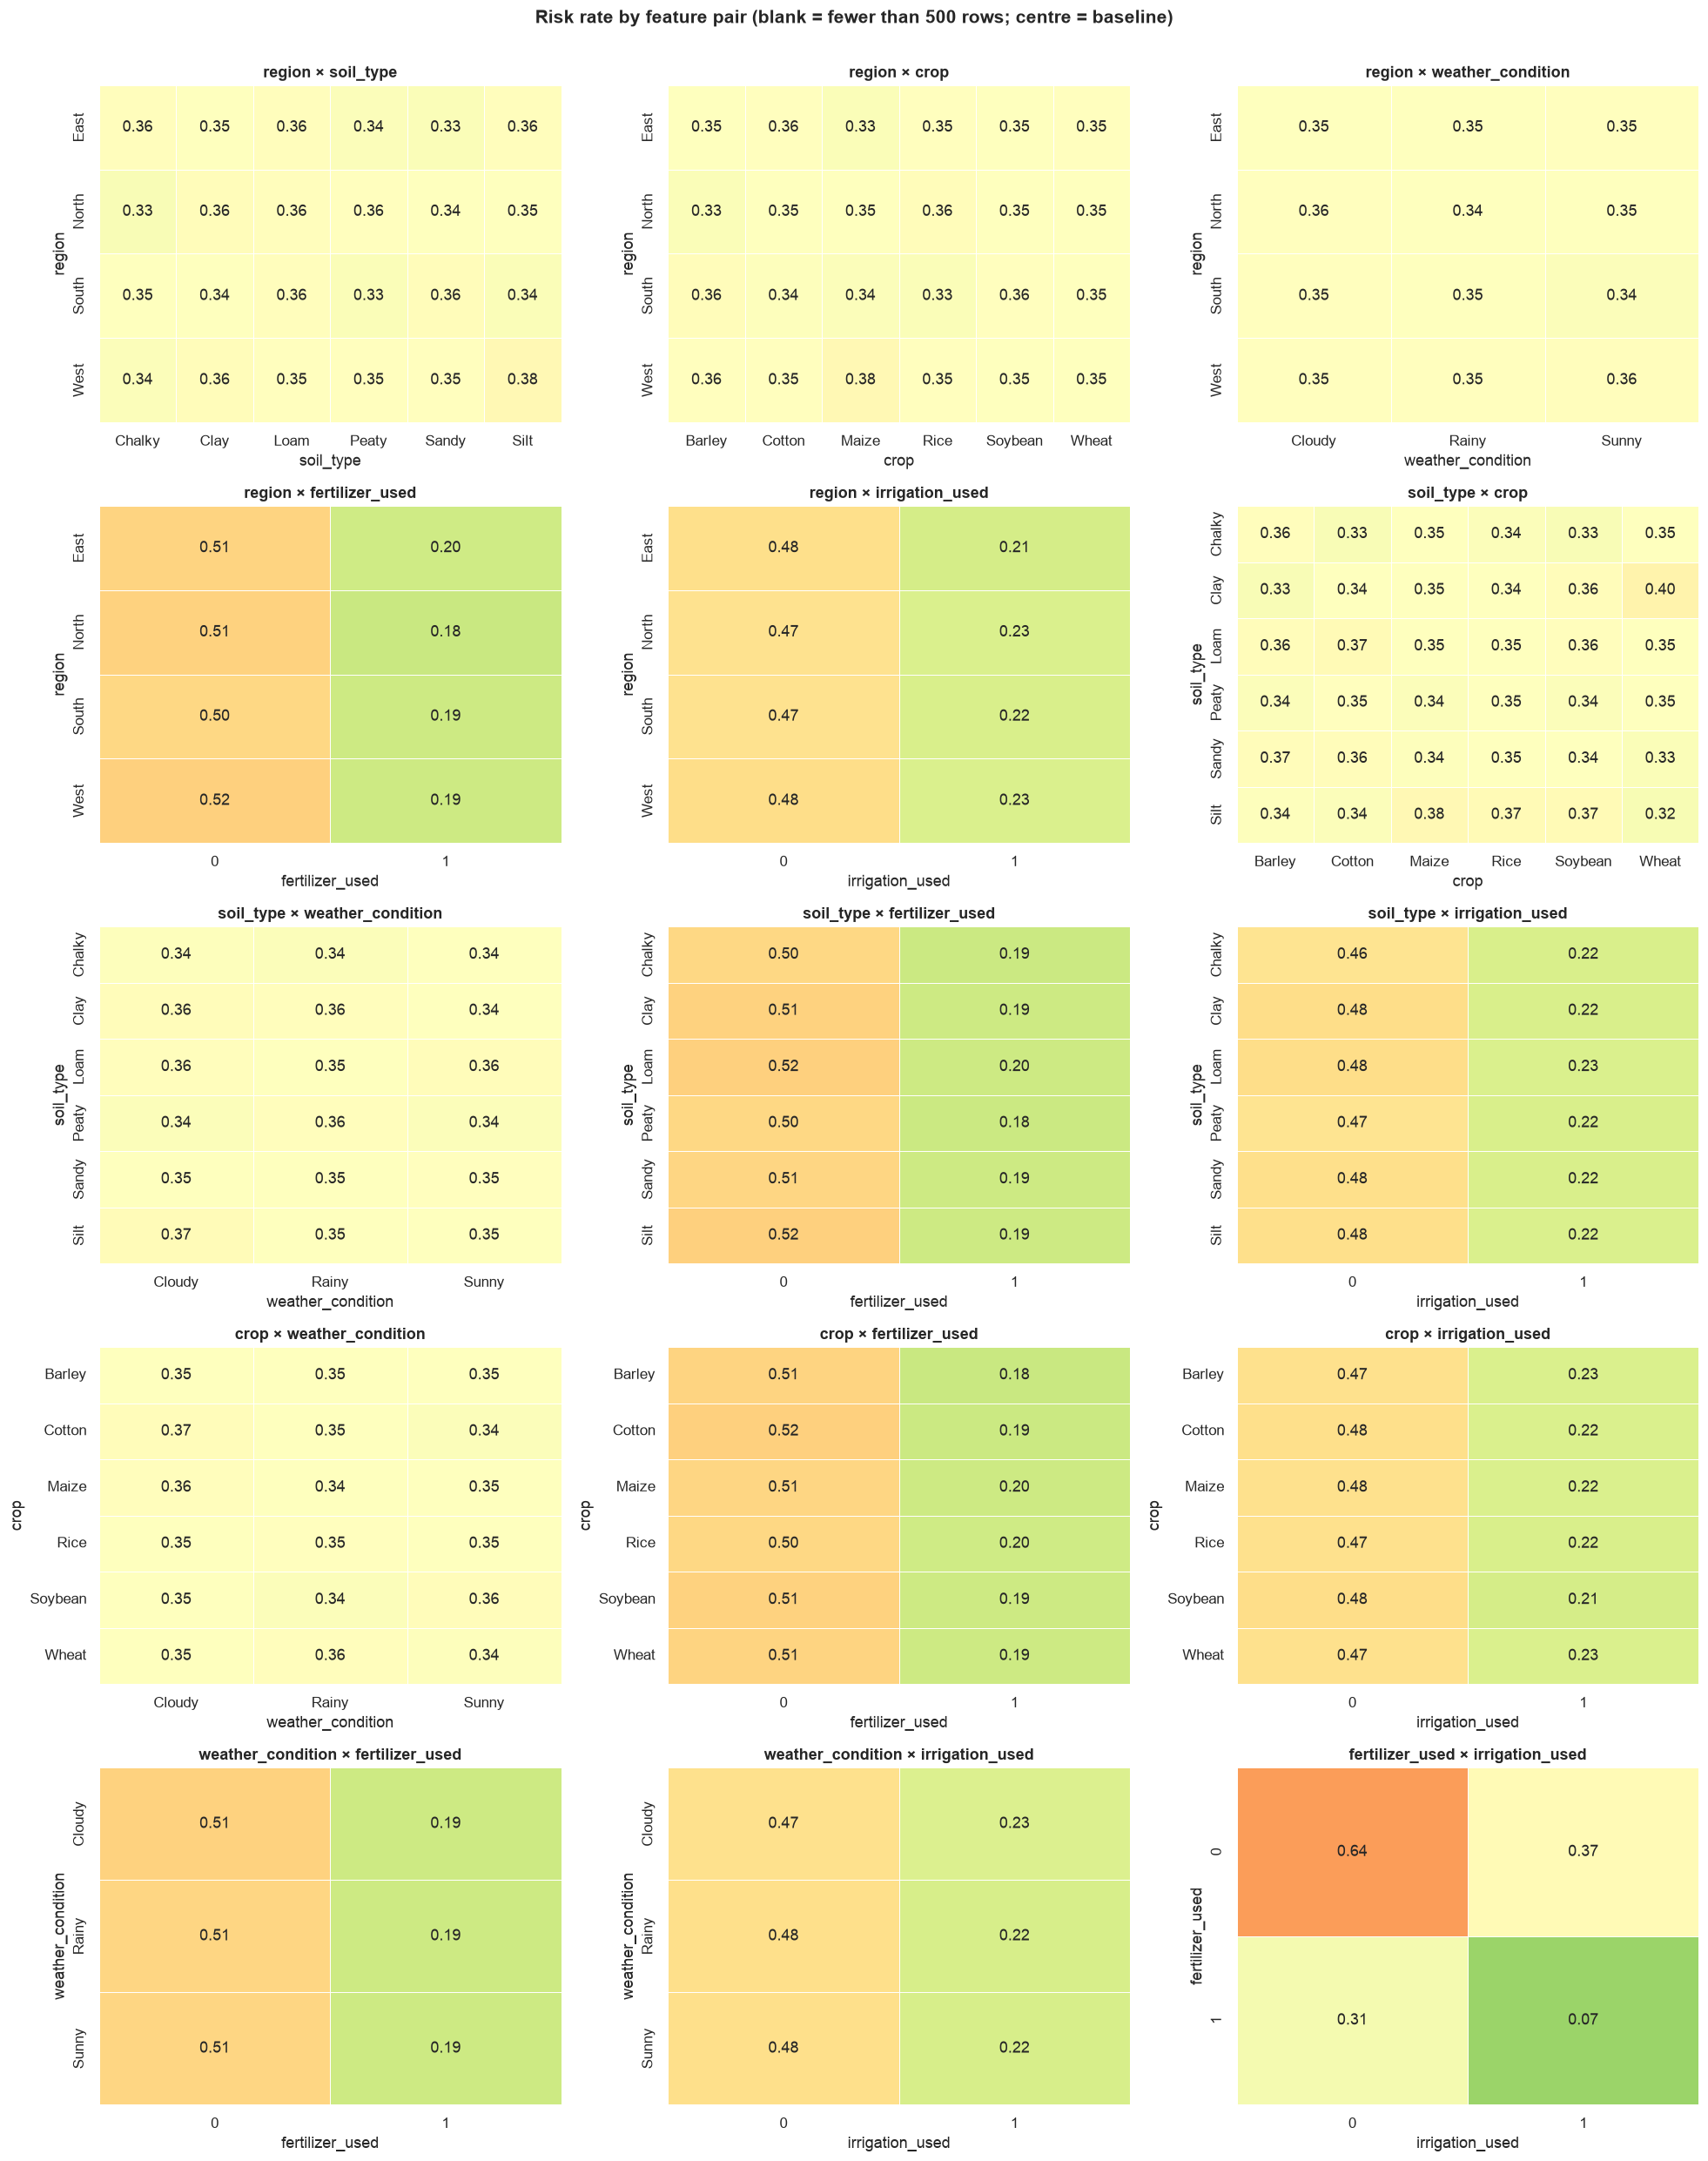

In [25]:
pairs = list(combinations(CATEGORICAL_COLS + FLAGS, 2))
ncols = 3
nrows = int(np.ceil(len(pairs) / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 4.5 * nrows))

for ax, (a, b) in zip(axes.ravel(), pairs):
    rate = data.groupby([a, b])[TARGET_COL].mean().unstack()
    n    = data.groupby([a, b]).size().unstack()
    sns.heatmap(rate.where(n >= MIN_N), annot=True, fmt=".2f", cmap="RdYlGn_r",
                center=BASE, vmin=0, vmax=1, cbar=False, ax=ax, linewidths=0.5)
    ax.set_title(f"{a} × {b}")

for ax in axes.ravel()[len(pairs):]:
    ax.axis("off")

plt.suptitle(f"Risk rate by feature pair (blank = fewer than {MIN_N} rows; centre = baseline)",
             y=1.002, fontsize=14, fontweight="bold")
plt.tight_layout(); plt.show()

In [26]:
bins = {"rainfall_mm": "rain_bin", "temperature_c": "temp_bin", "days_to_harvest": "days_bin"}
df_b = data[CATEGORICAL_COLS + FLAGS + [TARGET_COL]].copy()
for col, name in bins.items():
    df_b[name] = pd.qcut(data[col], 4, duplicates="drop", precision=1).astype(str)

COMBO_FEATS = CATEGORICAL_COLS + FLAGS + list(bins.values())

In [27]:
def combo_table(data, features, TARGET=TARGET_COL, ks=(2, 3), min_n=MIN_N):
    """Risk rate for every value-combination of k features.
    lift    = rate / baseline
    z       = how many standard errors the rate is from the baseline
    synergy = observed rate minus what the single features predict additively
              (large |synergy| means a true interaction, not just two strong features)."""
    base = data[TARGET].mean()
    marg = {f: data.groupby(f)[TARGET].mean() for f in features}
    out = []
    for k in ks:
        for cols in combinations(features, k):
            cols = list(cols)
            g = data.groupby(cols, observed=True)[TARGET].agg(n="size", rate="mean").reset_index()
            g = g[g["n"] >= min_n]
            if g.empty:
                continue
            expected = sum(g[c].map(marg[c]) for c in cols) - (k - 1) * base
            g["combo"] = g[cols].apply(lambda r: " & ".join(f"{c}={r[c]}" for c in cols), axis=1)
            g["k"] = k
            g["lift"] = g["rate"] / base
            g["z"] = (g["rate"] - base) / np.sqrt(base * (1 - base) / g["n"])
            g["synergy"] = g["rate"] - expected
            out.append(g[["combo", "k", "n", "rate", "lift", "z", "synergy"]])
    return pd.concat(out, ignore_index=True)

In [28]:
res = combo_table(df_b, COMBO_FEATS)
print(f"{len(res):,} combinations with n >= {MIN_N}")

print("\nMost RISKY combinations")
display(res.sort_values("z", ascending=False).head(15).reset_index(drop=True))
print("\nMost PROTECTIVE combinations")
display(res.sort_values("z").head(15).reset_index(drop=True))
print("\nStrongest true INTERACTIONS (effect beyond the sum of parts, |z| > 2)")
display(res[res["z"].abs() > 2].sort_values("synergy", key=abs, ascending=False)
        .head(15).reset_index(drop=True))

4,349 combinations with n >= 500

Most RISKY combinations


,combo,k,n,rate,lift,z,synergy
0,"fertilizer_used=0 & rain_bin=(99.9, 325.9]",2,6259,0.985,2.815,105.376,0.035
1,"irrigation_used=0 & rain_bin=(99.9, 325.9]",2,6291,0.954,2.725,100.371,0.036
2,fertilizer_used=0 & irrigation_used=0 & rain_b...,3,3166,1.000,2.857,76.679,-0.077
3,fertilizer_used=0 & irrigation_used=0 & rain_b...,3,3209,0.974,2.784,74.163,0.234
4,fertilizer_used=0 & irrigation_used=1 & rain_b...,3,3093,0.970,2.772,72.322,0.147
5,fertilizer_used=0 & irrigation_used=0,2,12605,0.643,1.836,68.856,0.007
6,"fertilizer_used=0 & rain_bin=(325.9, 550.3]",2,6275,0.745,2.128,65.552,0.131
7,fertilizer_used=1 & irrigation_used=0 & rain_b...,3,3125,0.907,2.590,65.230,0.148
8,weather_condition=Cloudy & fertilizer_used=0 &...,3,2134,0.986,2.817,61.592,0.033
9,weather_condition=Rainy & fertilizer_used=0 & ...,3,2086,0.983,2.809,60.635,0.034



Most PROTECTIVE combinations


,combo,k,n,rate,lift,z,synergy
0,fertilizer_used=1 & irrigation_used=1,2,12514,0.073,0.207,-65.070,0.009
1,"fertilizer_used=1 & rain_bin=(774.4, 1000.0]",2,6269,0.000,0.000,-58.100,0.150
2,"irrigation_used=1 & rain_bin=(774.4, 1000.0]",2,6242,0.000,0.000,-57.975,0.118
3,"fertilizer_used=1 & rain_bin=(550.3, 774.4]",2,6228,0.004,0.011,-57.272,0.019
4,"irrigation_used=1 & rain_bin=(550.3, 774.4]",2,6345,0.016,0.046,-55.766,-0.002
5,"irrigation_used=0 & rain_bin=(774.4, 1000.0]",2,6258,0.019,0.055,-54.842,-0.117
6,"fertilizer_used=0 & rain_bin=(774.4, 1000.0]",2,6231,0.019,0.055,-54.710,-0.149
7,"weather_condition=Cloudy & rain_bin=(774.4, 10...",2,4204,0.010,0.030,-46.156,-0.002
8,"weather_condition=Sunny & rain_bin=(774.4, 100...",2,4140,0.009,0.025,-46.042,0.000
9,"weather_condition=Rainy & rain_bin=(774.4, 100...",2,4156,0.010,0.028,-45.972,0.001



Strongest true INTERACTIONS (effect beyond the sum of parts, |z| > 2)


,combo,k,n,rate,lift,z,synergy
0,fertilizer_used=1 & irrigation_used=1 & rain_b...,3,3178,0.000,0.000,-41.367,0.277
1,fertilizer_used=0 & irrigation_used=0 & rain_b...,3,3167,0.038,0.109,-36.788,-0.257
2,fertilizer_used=0 & irrigation_used=0 & rain_b...,3,3209,0.974,2.784,74.163,0.234
3,fertilizer_used=1 & irrigation_used=1 & rain_b...,3,3116,0.285,0.814,-7.609,-0.219
4,"fertilizer_used=1 & rain_bin=(774.4, 1000.0] &...",3,1503,0.000,0.000,-28.448,0.191
5,"fertilizer_used=0 & rain_bin=(774.4, 1000.0] &...",3,1495,0.034,0.097,-25.607,-0.180
6,"fertilizer_used=0 & rain_bin=(325.9, 550.3] & ...",3,1530,0.824,2.355,38.887,0.165
7,"fertilizer_used=1 & rain_bin=(774.4, 1000.0] &...",3,1555,0.000,0.000,-28.936,0.165
8,fertilizer_used=1 & irrigation_used=1 & rain_b...,3,3084,0.006,0.019,-39.996,-0.161
9,"irrigation_used=1 & rain_bin=(774.4, 1000.0] &...",3,1527,0.000,0.000,-28.675,0.159


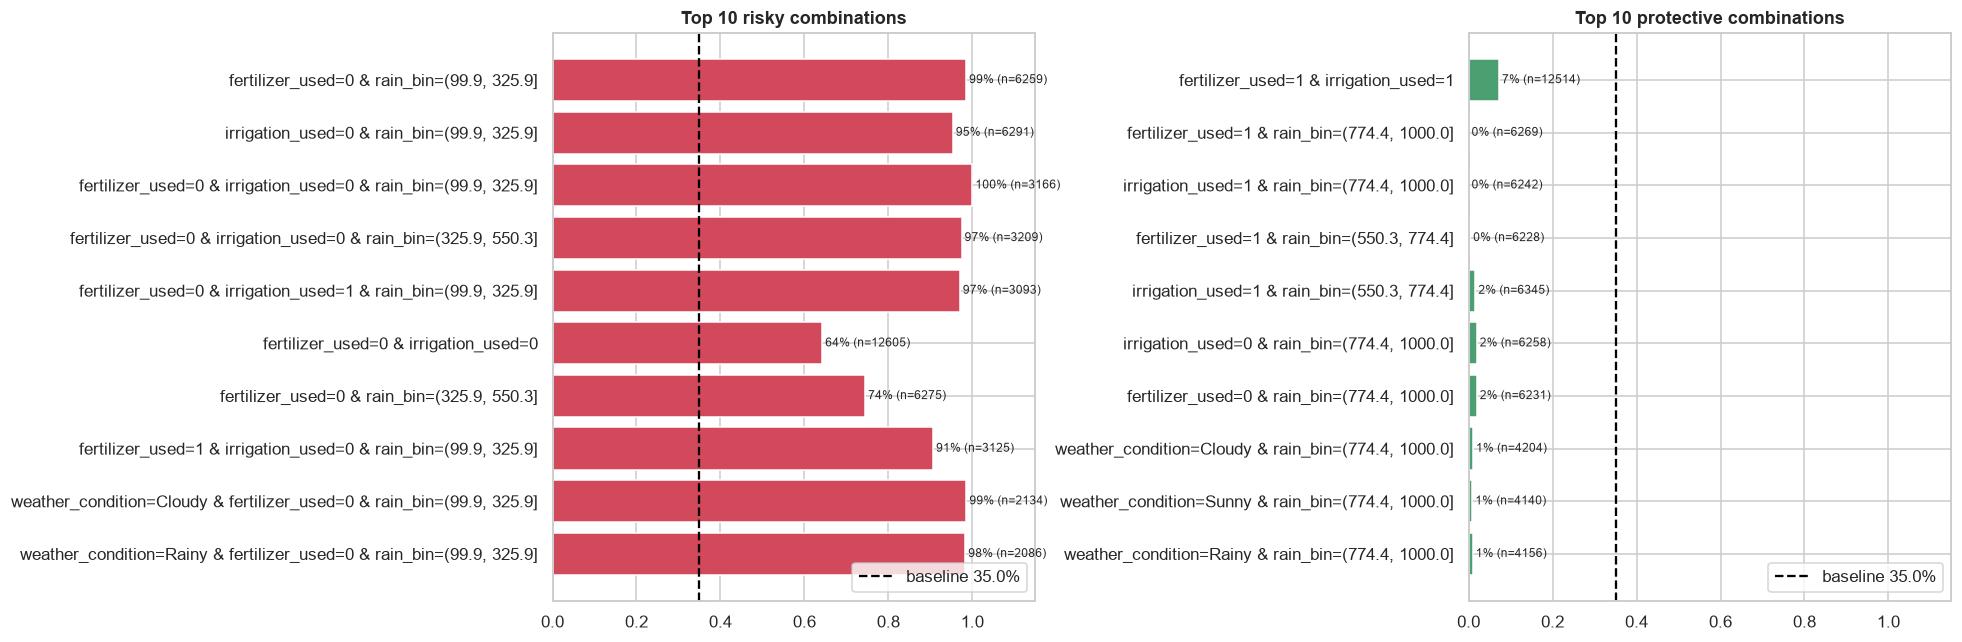

In [29]:
risky = res.sort_values("z", ascending=False).head(10).iloc[::-1]
safe  = res.sort_values("z").head(10).iloc[::-1]

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
for ax, sub_df, color, title in [(axes[0], risky, "#D1495B", "Top 10 risky combinations"),
                                 (axes[1], safe,  "#4C9F70", "Top 10 protective combinations")]:
    ax.barh(sub_df["combo"], sub_df["rate"], color=color)
    ax.axvline(BASE, color="black", ls="--", label=f"baseline {BASE:.1%}")
    for y, (r, n) in enumerate(zip(sub_df["rate"], sub_df["n"])):
        ax.text(r, y, f" {r:.0%} (n={n})", va="center", fontsize=8)
    ax.set_xlim(0, 1.15); ax.set_title(title); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

In [30]:
rng = np.random.RandomState(42)
split = rng.rand(len(df_b)) < 0.5
A, B = df_b[split], df_b[~split]

resA = combo_table(A, COMBO_FEATS, min_n=max(10, MIN_N // 2))
resB = combo_table(B, COMBO_FEATS, min_n=5)

top = resA.reindex(resA["z"].abs().sort_values(ascending=False).index).head(20)
rep = top.merge(resB[["combo", "n", "rate"]], on="combo", suffixes=("_A", "_B"))
rep["same_direction"] = np.sign(rep["rate_A"] - BASE) == np.sign(rep["rate_B"] - BASE)
display(rep[["combo", "n_A", "rate_A", "n_B", "rate_B", "same_direction"]].reset_index(drop=True))
print(f"Replication rate: {rep['same_direction'].mean():.0%} of the top combinations keep their direction on unseen data")

,combo,n_A,rate_A,n_B,rate_B,same_direction
0,"fertilizer_used=0 & rain_bin=(99.9, 325.9]",3128,0.984,3131,0.986,True
1,"irrigation_used=0 & rain_bin=(99.9, 325.9]",3137,0.952,3154,0.955,True
2,fertilizer_used=0 & irrigation_used=0 & rain_b...,1578,1.000,1588,1.000,True
3,fertilizer_used=0 & irrigation_used=0 & rain_b...,1601,0.973,1608,0.976,True
4,fertilizer_used=0 & irrigation_used=1 & rain_b...,1550,0.968,1543,0.972,True
5,fertilizer_used=0 & irrigation_used=0,6344,0.637,6261,0.649,True
6,"fertilizer_used=0 & rain_bin=(325.9, 550.3]",3139,0.743,3136,0.747,True
7,fertilizer_used=1 & irrigation_used=0 & rain_b...,1559,0.903,1566,0.910,True
8,fertilizer_used=1 & irrigation_used=1,6206,0.073,6308,0.072,True
9,weather_condition=Sunny & fertilizer_used=0 & ...,1045,0.986,994,0.988,True


Replication rate: 100% of the top combinations keep their direction on unseen data


**What the output says:**
- **Extreme risk without inputs in dry conditions:** `fertilizer_used=0 & irrigation_used=0 & rain_bin=(99.9, 325.9]` hits **`100.0%` risk** (`n = 3,166`, lift `2.86×`).
- **Combined input effect:** neither input (`0 & 0`) gives **`64.3%`** risk vs **`7.3%`** when both are used (`1 & 1`).
- **Wet floor:** above `774 mm` with either input, risk drops to **`0.0%`**.
- **100% replication:** every top-20 combination keeps the same direction across unseen split halves, confirming real structure rather than sampling noise.

### 2.8 Continuous × Binary Interactions & Per-Crop Risk Surfaces

Examine how `fertilizer_used` and `irrigation_used` shift numeric risk curves, and check whether the `rainfall × temperature` risk surface differs by crop.

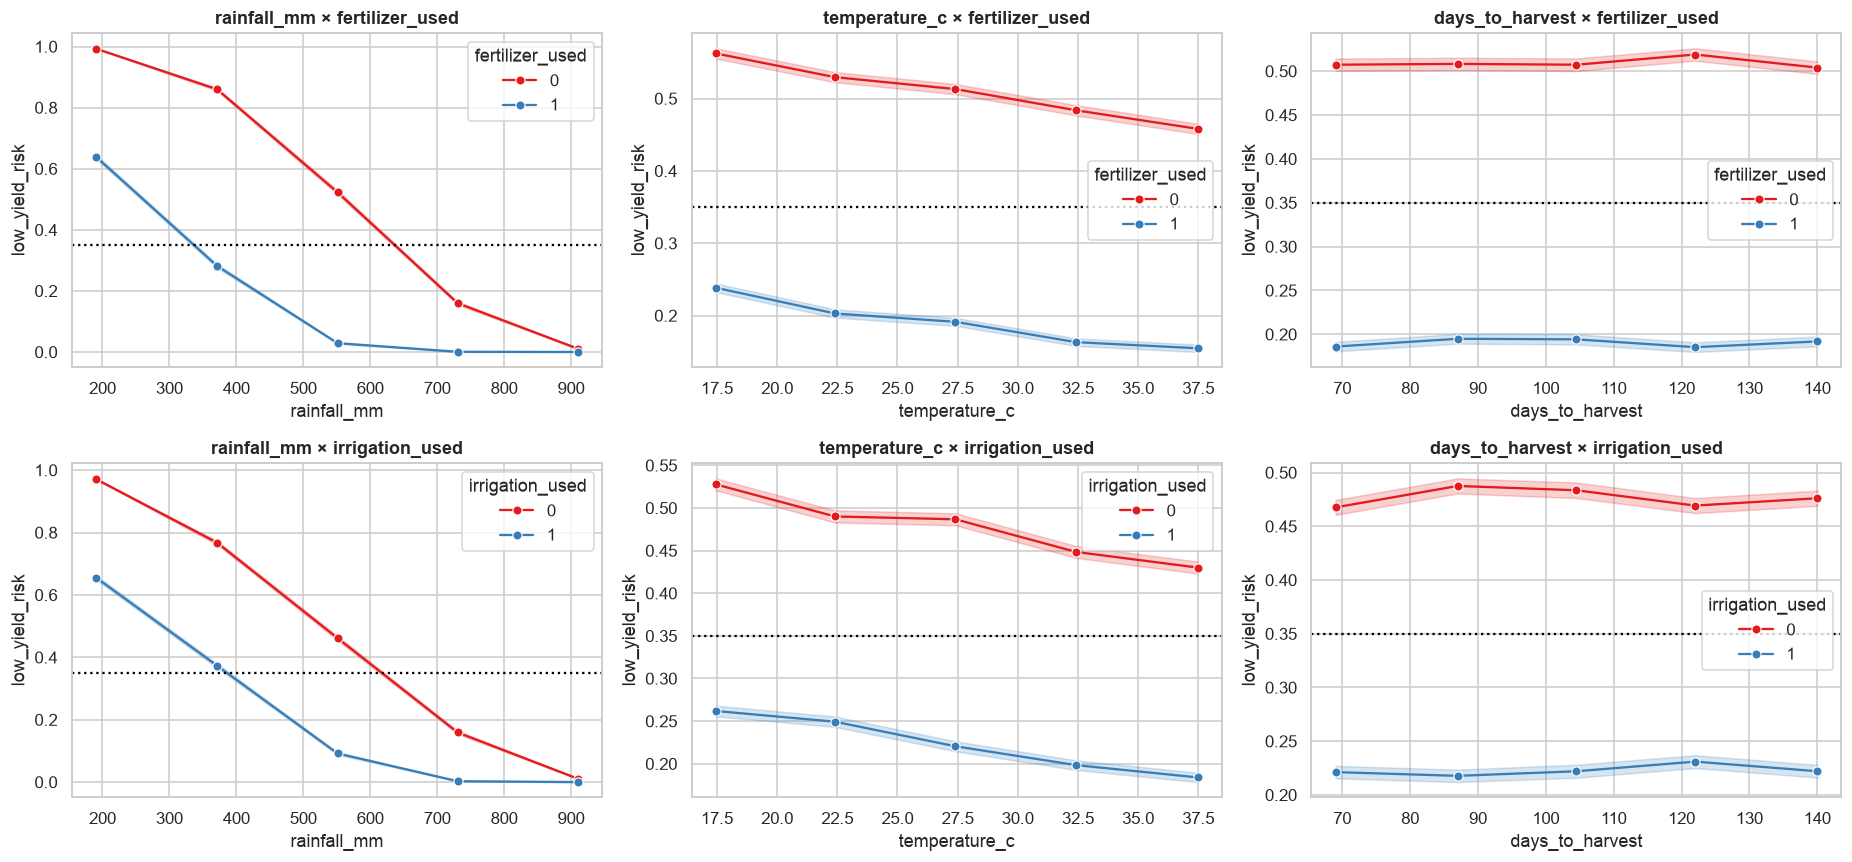

In [31]:
fig, axes = plt.subplots(2, 3, figsize=(17, 8))
for r, flag in enumerate(FLAGS):
    for c, col in enumerate(NUMERIC_COLS):
        tmp = data.copy()
        tmp["bin_mid"] = pd.qcut(tmp[col], 5, duplicates="drop").map(lambda iv: iv.mid).astype(float)
        sns.lineplot(data=tmp, x="bin_mid", y=TARGET_COL, hue=flag, marker="o",
                     errorbar="se", palette="Set1", ax=axes[r, c])
        axes[r, c].axhline(BASE, color="black", ls=":")
        axes[r, c].set_title(f"{col} × {flag}"); axes[r, c].set_xlabel(col)
plt.tight_layout(); plt.show()

In [32]:
tmp = data.copy()
tmp["rain_q"] = pd.qcut(tmp["rainfall_mm"], 4, labels=["Q1 driest", "Q2", "Q3", "Q4 wettest"])
tmp["temp_q"] = pd.qcut(tmp["temperature_c"], 4, labels=["Q1 coolest", "Q2", "Q3", "Q4 hottest"])

In [33]:
def surface(data, ax, min_n, title, TARGET=TARGET_COL):
    rate = data.groupby(["rain_q", "temp_q"], observed=True)[TARGET].mean().unstack()
    n = data.groupby(["rain_q", "temp_q"], observed=True).size().unstack()
    sns.heatmap(rate.where(n >= min_n), annot=True, fmt=".2f", cmap="RdYlGn_r",
                center=BASE, vmin=0, vmax=1, cbar=False, ax=ax, linewidths=0.5)
    ax.set_title(title); ax.set_xlabel("temperature quartile"); ax.set_ylabel("rainfall quartile")

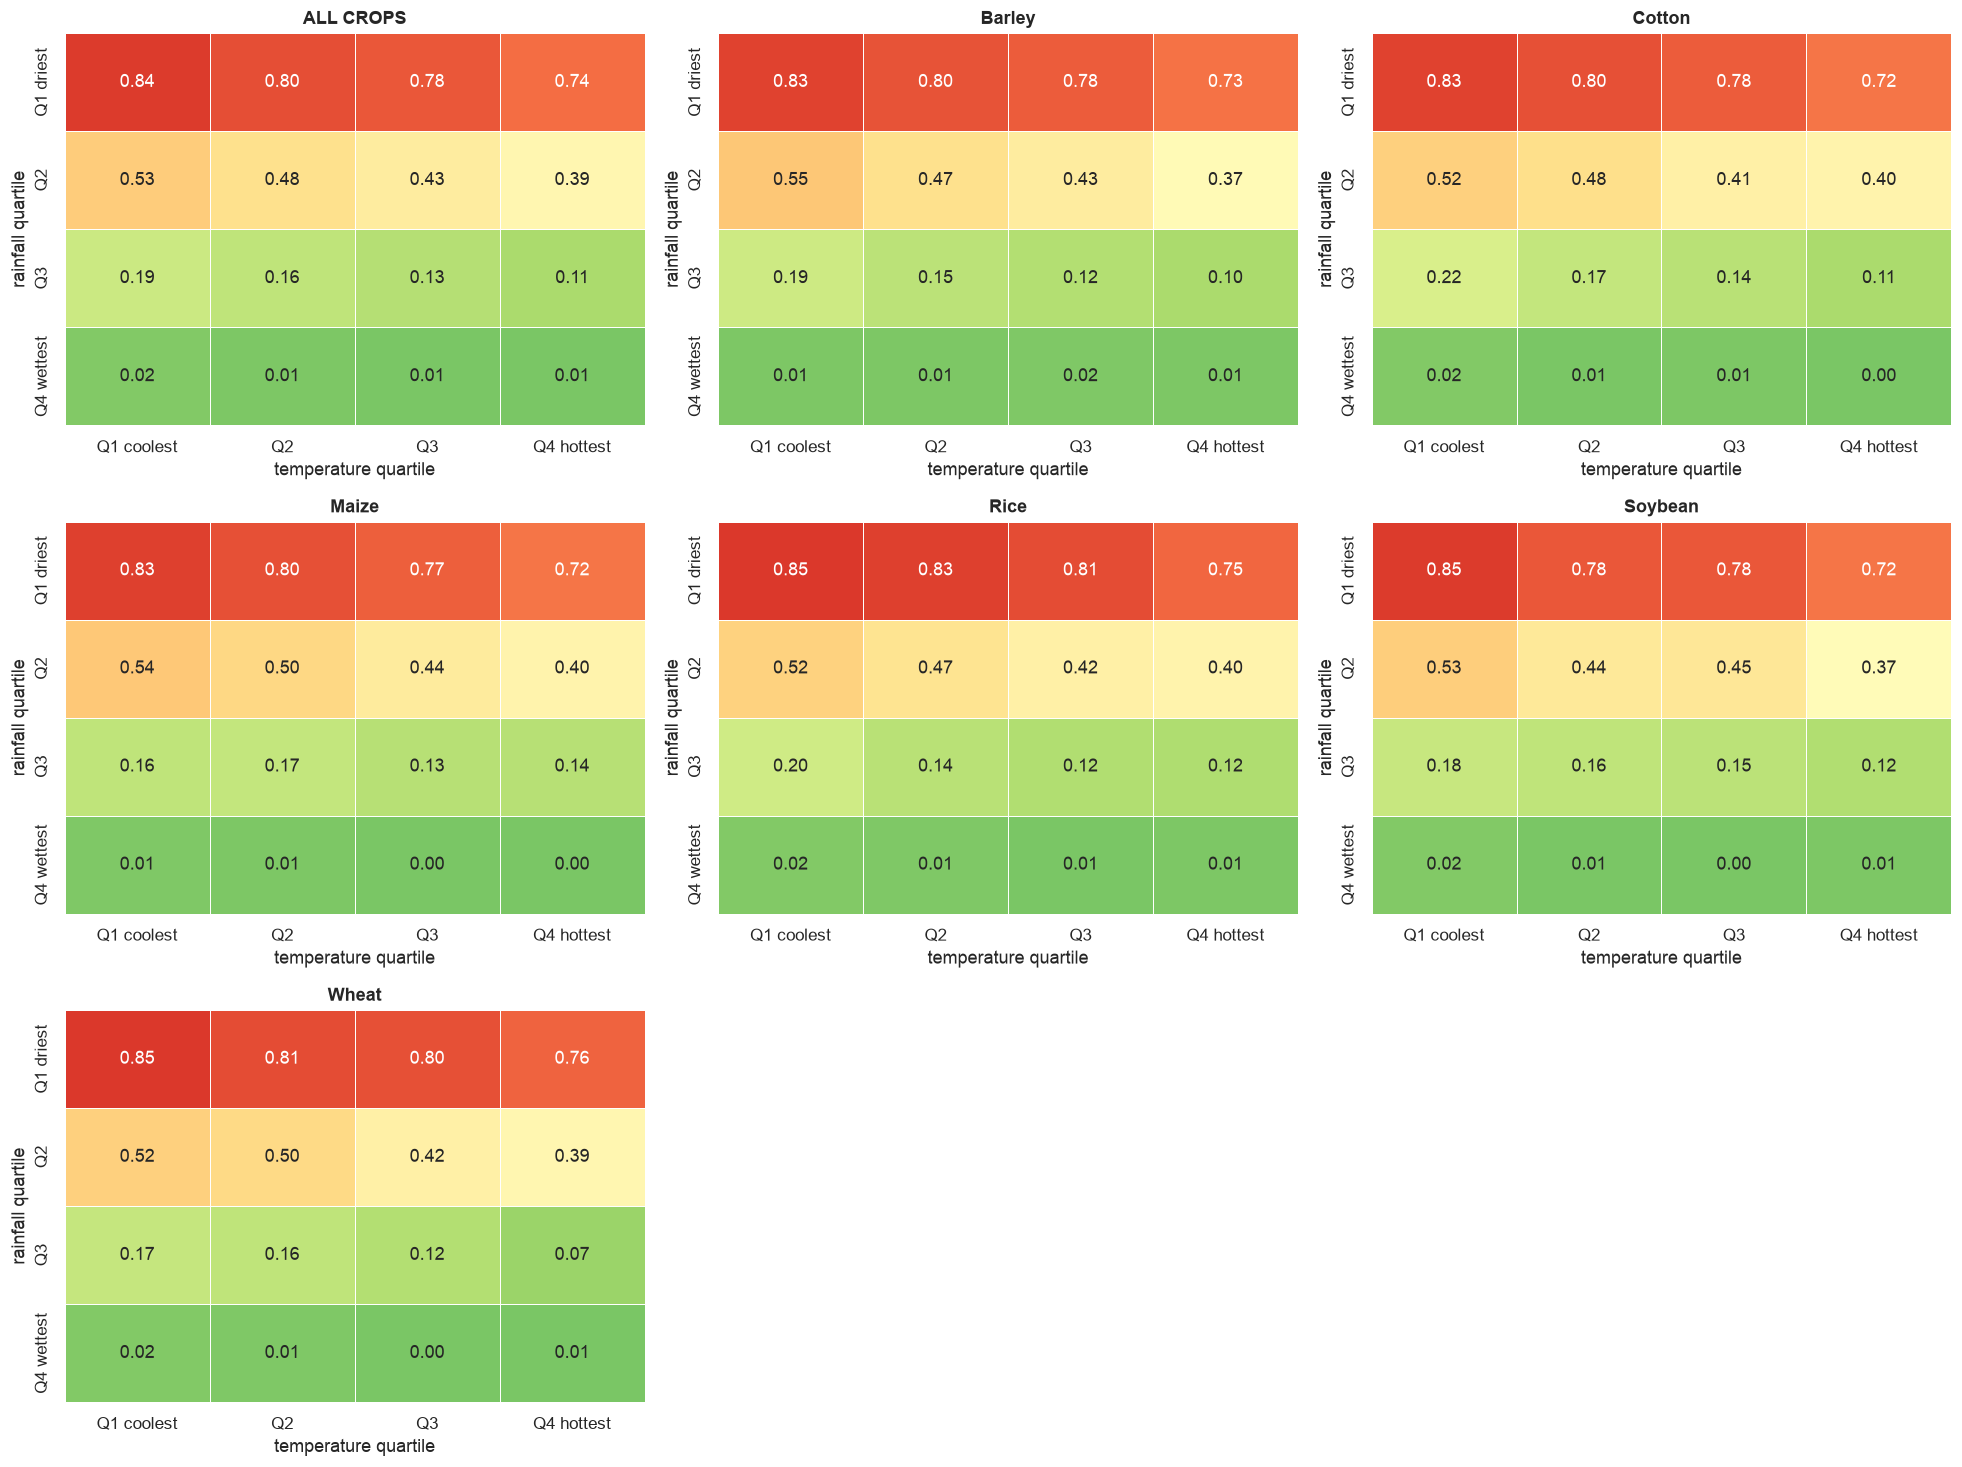

In [34]:
crops = sorted(tmp["crop"].unique())
ncols = 3
nrows = int(np.ceil((len(crops) + 1) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 4.5 * nrows))
axes = axes.ravel()
surface(tmp, axes[0], MIN_N, "ALL CROPS")

for ax, crop in zip(axes[1:], crops):
    surface(tmp[tmp["crop"] == crop], ax, 10, crop)

for ax in axes[len(crops) + 1:]:
    ax.axis("off")

plt.tight_layout(); plt.show()

**What the output says:**
- **Inputs shift the rainfall curve right:** around `550 mm`, fertilizer cuts risk from `~52%` to `~3%`, and irrigation from `~46%` to `~9%`. Under severe drought (`~190 mm`), risk remains `~64–65%` even with one input — motivating interaction terms (`rain_x_inputs`, `deficit_x_noinputs`).
- **Crops behave identically:** all 6 per-crop heatmaps match `ALL CROPS` nearly cell-for-cell, confirming crop-specific features add no value.

### 2.9 Feature-to-Feature Independence (Kruskal-Wallis & Cramér's V)

Test whether numeric distributions differ across categories (Kruskal-Wallis) and measure categorical/binary associations with the target and with each other (Cramér's V).

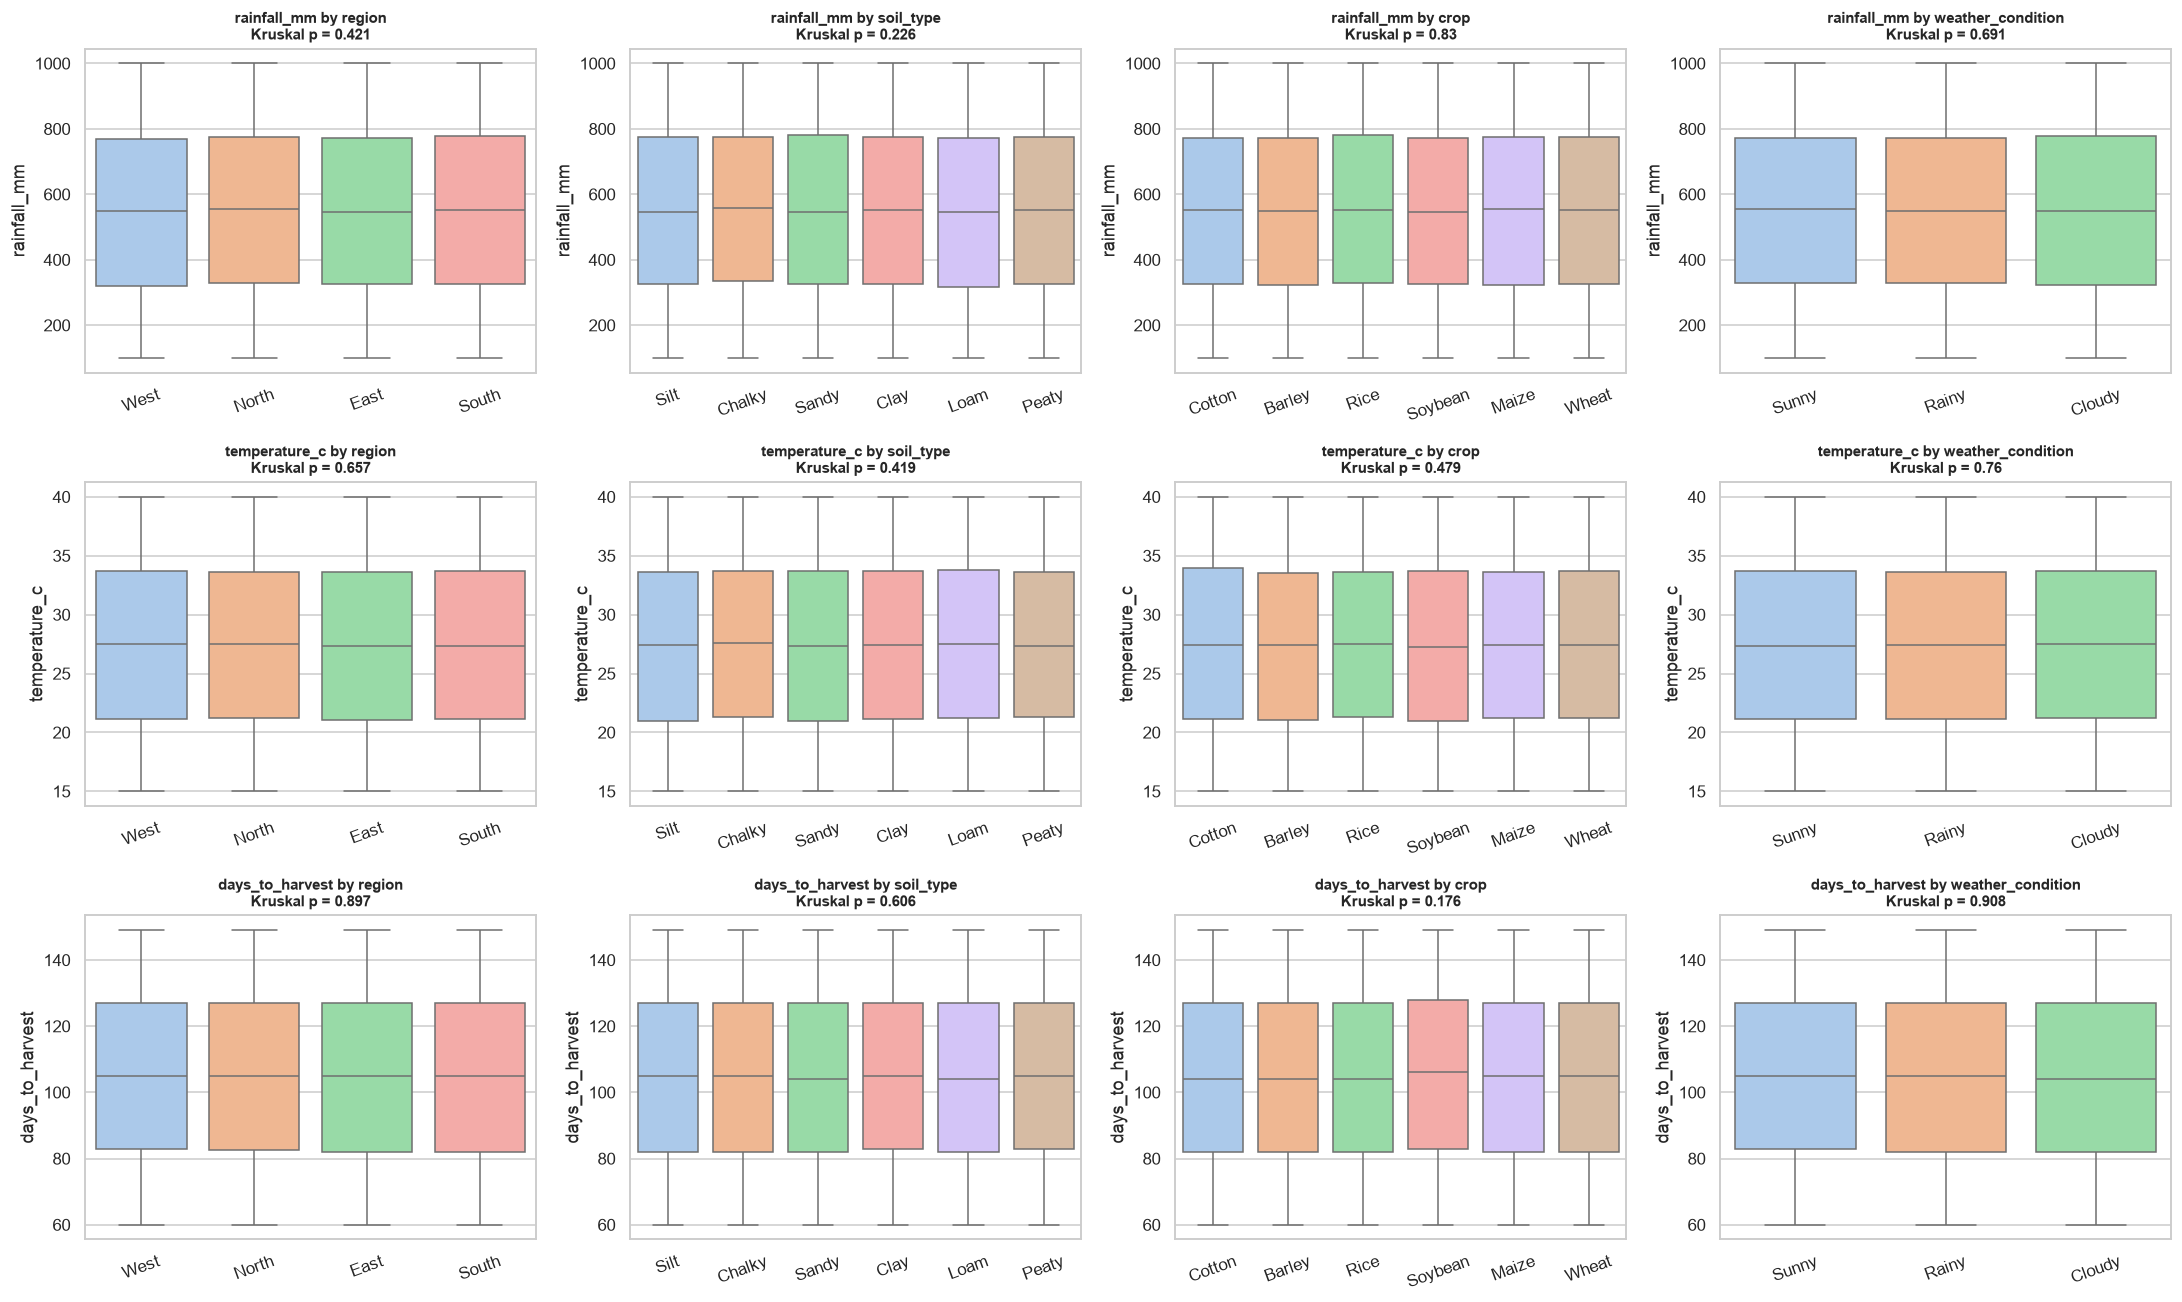

In [35]:
fig, axes = plt.subplots(len(NUMERIC_COLS), len(CATEGORICAL_COLS), figsize=(5 * len(CATEGORICAL_COLS), 4 * len(NUMERIC_COLS)))
for i, num in enumerate(NUMERIC_COLS):
    for j, cat in enumerate(CATEGORICAL_COLS):
        groups = [g[num].values for _, g in data.groupby(cat)]
        
        p = stats.kruskal(*groups).pvalue if len(groups) > 1 else np.nan
        
        sns.boxplot(data=data, x=cat, y=num, hue=cat, legend=False, ax=axes[i, j], palette="pastel")
        
        axes[i, j].set_title(f"{num} by {cat}\nKruskal p = {p:.3g}", fontsize=10)
        axes[i, j].tick_params(axis="x", rotation=20); axes[i, j].set_xlabel("")

plt.tight_layout()
plt.show()

In [36]:
def cramers_v(x, y):
    ct = pd.crosstab(x, y)
    chi2, p, _, _ = stats.chi2_contingency(ct)
    n = ct.values.sum(); r, k = ct.shape
    return np.sqrt((chi2 / n) / max(1, min(k - 1, r - 1))), p

In [37]:
tv = pd.DataFrame([{"feature": c, "cramers_v": cramers_v(data[c], data[TARGET_COL])[0],
                    "p_value": cramers_v(data[c], data[TARGET_COL])[1]} for c in CATEGORICAL_COLS + FLAGS]
                  ).sort_values("cramers_v", ascending=False)
display(tv.set_index("feature"))

,cramers_v,p_value
feature,,
fertilizer_used,0.334,0.000
irrigation_used,0.266,0.000
soil_type,0.012,0.225
region,0.007,0.465
weather_condition,0.004,0.693
crop,0.000,1.000


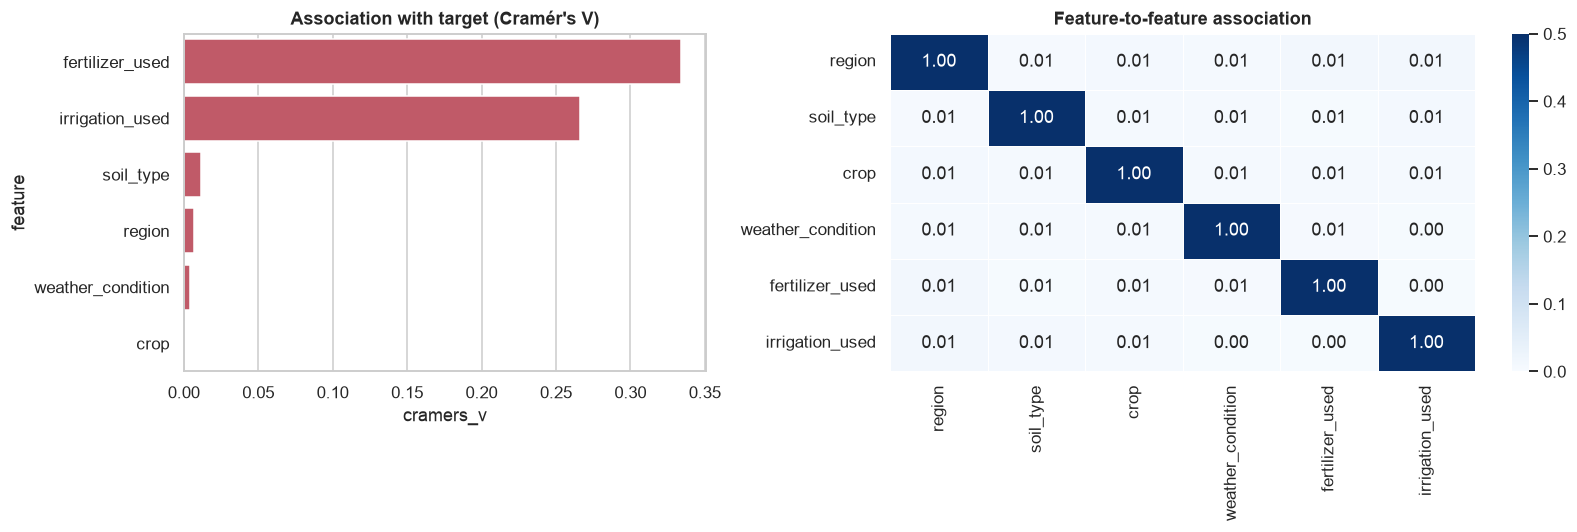

In [38]:
cf = CATEGORICAL_COLS + FLAGS
mat = pd.DataFrame(1.0, index=cf, columns=cf)
for a, b in combinations(cf, 2):
    mat.loc[a, b] = mat.loc[b, a] = cramers_v(data[a], data[b])[0]

fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1, 1.4]})

sns.barplot(data=tv, y="feature", x="cramers_v", color="#D1495B", ax=axes[0])
axes[0].set_title("Association with target (Cramér's V)")

sns.heatmap(mat, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=0.5, ax=axes[1], linewidths=0.5)
axes[1].set_title("Feature-to-feature association")

plt.tight_layout()
plt.show()

**What the output says:**
- **Predictors are mutually independent:** Kruskal-Wallis `p > 0.17` across all numeric × categorical pairs, and feature-to-feature Cramér's V is `≤ 0.01` everywhere.
- **Target Cramér's V confirms signal vs noise:** only `fertilizer_used (0.334)` and `irrigation_used (0.266)` matter among non-continuous columns; `soil_type (0.012)`, `region (0.007)`, `weather_condition (0.004)`, and `crop (0.000)` are independent noise.

## 3. Data Cleaning (Modular In-Notebook Pipeline)

Reuses `DATA_PATH`, `CLEAN_PATH`, `logger`, `CleaningLog`, and all schema/rule constants defined in Section 0.1. The cleaning pipeline is split into 5 small, single-responsibility subfunctions called by one orchestrator (`clean_crop_data`).

### 3.1 Subfunctions: Text Normalization & Type Coercion

In [39]:
def normalize_text_columns(df: pd.DataFrame, log: CleaningLog) -> pd.DataFrame:
    """Strip whitespace, replace placeholder tokens with NA, and apply Title Case."""
    out = df.copy()
    ws = 0
    for col in CATEGORICAL_COLS:
        raw_s = out[col].astype("string")
        stripped = raw_s.str.strip()
        ws += int((raw_s != stripped).sum())
        out[col] = stripped.mask(stripped.str.lower().isin(MISSING_TOKENS)).str.title()
    log.add("Text", "Whitespace, case, placeholder tokens", "Stripped, Title Case, placeholders -> NA", ws)
    return out


def coerce_column_types(df: pd.DataFrame, log: CleaningLog) -> pd.DataFrame:
    """Coerce numeric columns to float/int and binary columns to nullable Int8 (0/1)."""
    out = df.copy()
    for col in NUMERIC_COLS:
        before = int(out[col].isna().sum())
        out[col] = pd.to_numeric(out[col], errors="coerce")
        log.add("Data types", f"{col} must be numeric", "pd.to_numeric(errors='coerce')",
                int(out[col].isna().sum()) - before)

    for col in BINARY_COLS:
        s = out[col].astype("string").str.strip().str.lower()
        before = int(out[col].isna().sum())
        out[col] = s.map(BINARY_MAP).astype("Int8")
        log.add("Data types", f"{col} must be 0/1", "Mapped yes/no/true/false/1/0; else -> NA",
                int(out[col].isna().sum()) - before)
    return out

### 3.2 Subfunctions: Domain Range Validation, Missing Values & Duplicates

In [40]:
def validate_ranges(df: pd.DataFrame, log: CleaningLog) -> pd.DataFrame:
    """Set out-of-range numeric values to NA for downstream imputation."""
    out = df.copy()
    for col, (lo, hi) in VALID_RANGES.items():
        bad = (out[col] < lo) | (out[col] > hi)
        out.loc[bad, col] = np.nan
        log.add("Validation", f"{col} outside [{lo}, {hi}]", "Set to NA, then imputed", int(bad.sum()))
    return out


def handle_missing_and_duplicates(df: pd.DataFrame, log: CleaningLog) -> pd.DataFrame:
    """Drop missing targets, impute missing features, and remove exact duplicate rows."""
    out = df.copy()

    n_target_na = int(out[TARGET_COL].isna().sum())
    out = out.dropna(subset=[TARGET_COL])
    log.add("Missing values", f"Missing {TARGET_COL}", "Rows dropped", n_target_na)

    for col in NUMERIC_COLS:
        n = int(out[col].isna().sum())
        out[col] = out[col].fillna(out[col].median())
        log.add("Missing values", f"{col} missing", "Global median (Kruskal p > 0.17 across crops)", n)

    for col in FLAGS:
        n = int(out[col].isna().sum())
        if n:
            out[col] = out[col].fillna(out[col].mode().iloc[0])
        log.add("Missing values", f"{col} missing", "Mode", n)

    for col in CATEGORICAL_COLS:
        n = int(out[col].isna().sum())
        out[col] = out[col].fillna("Unknown")
        log.add("Missing values", f"{col} missing", "Filled with 'Unknown'", n)

    n_dup = int(out.duplicated().sum())
    out = out.drop_duplicates()
    log.add("Duplicates", "Exact duplicate rows", "Dropped, kept first", n_dup)
    return out

### 3.3 Subfunction & Orchestrator: Finalize Dtypes & `clean_crop_data()`

In [41]:
def finalize_dtypes(df: pd.DataFrame, n0: int, log: CleaningLog) -> pd.DataFrame:
    """Cast columns to compact dtypes, reset index, and assert zero remaining nulls."""
    out = df.copy()
    out[CATEGORICAL_COLS] = out[CATEGORICAL_COLS].astype("category")
    out[FLOAT_COLS] = out[FLOAT_COLS].astype("float64")
    out["days_to_harvest"] = out["days_to_harvest"].round().astype("int16")
    out[BINARY_COLS] = out[BINARY_COLS].astype("int8")
    out = out.reset_index(drop=True)
    log.add("Final", f"{n0} rows in", f"{len(out)} rows out; category/float64/int16/int8", n0 - len(out))
    assert out.isna().sum().sum() == 0, "Nulls remain after cleaning"
    return out


def clean_crop_data(df: pd.DataFrame, log: CleaningLog | None = None) -> pd.DataFrame:
    """Run the full cleaning pipeline by chaining the 5 subfunctions."""
    log = log if log is not None else CleaningLog()
    missing_cols = set(EXPECTED_COLS) - set(df.columns)
    if missing_cols:
        raise ValueError(f"Missing required columns: {sorted(missing_cols)}")

    out = df[EXPECTED_COLS].copy()
    n0 = len(out)
    out = normalize_text_columns(out, log)
    out = coerce_column_types(out, log)
    out = validate_ranges(out, log)
    out = handle_missing_and_duplicates(out, log)
    out = finalize_dtypes(out, n0, log)
    return out

### 3.4 Run Cleaning Pipeline & Inspect Audit Log

In [42]:
cleaning_log = CleaningLog()
clean_df = clean_crop_data(raw_df, cleaning_log)

raw_mb = raw_df.memory_usage(deep=True).sum() / 1e6
clean_mb = clean_df.memory_usage(deep=True).sum() / 1e6
print(f"Shape: {raw_df.shape} -> {clean_df.shape} | Memory: {raw_mb:.2f} MB -> {clean_mb:.2f} MB")
display(cleaning_log.to_dataframe())

INFO | Text | Whitespace, case, placeholder tokens -> Stripped, Title Case, placeholders -> NA (0 affected)
INFO | Data types | rainfall_mm must be numeric -> pd.to_numeric(errors='coerce') (0 affected)
INFO | Data types | temperature_c must be numeric -> pd.to_numeric(errors='coerce') (0 affected)
INFO | Data types | days_to_harvest must be numeric -> pd.to_numeric(errors='coerce') (0 affected)
INFO | Data types | fertilizer_used must be 0/1 -> Mapped yes/no/true/false/1/0; else -> NA (0 affected)
INFO | Data types | irrigation_used must be 0/1 -> Mapped yes/no/true/false/1/0; else -> NA (0 affected)
INFO | Data types | low_yield_risk must be 0/1 -> Mapped yes/no/true/false/1/0; else -> NA (0 affected)
INFO | Validation | rainfall_mm outside [0, 5000] -> Set to NA, then imputed (0 affected)
INFO | Validation | temperature_c outside [-10, 60] -> Set to NA, then imputed (0 affected)
INFO | Validation | days_to_harvest outside [1, 400] -> Set to NA, then imputed (0 affected)
INFO | Missi

Shape: (50000, 10) -> (50000, 10) | Memory: 13.20 MB -> 1.25 MB


,step,issue,action,rows_affected
0,Text,"Whitespace, case, placeholder tokens","Stripped, Title Case, placeholders -> NA",0
1,Data types,rainfall_mm must be numeric,pd.to_numeric(errors='coerce'),0
2,Data types,temperature_c must be numeric,pd.to_numeric(errors='coerce'),0
3,Data types,days_to_harvest must be numeric,pd.to_numeric(errors='coerce'),0
4,Data types,fertilizer_used must be 0/1,Mapped yes/no/true/false/1/0; else -> NA,0
5,Data types,irrigation_used must be 0/1,Mapped yes/no/true/false/1/0; else -> NA,0
6,Data types,low_yield_risk must be 0/1,Mapped yes/no/true/false/1/0; else -> NA,0
7,Validation,"rainfall_mm outside [0, 5000]","Set to NA, then imputed",0
8,Validation,"temperature_c outside [-10, 60]","Set to NA, then imputed",0
9,Validation,"days_to_harvest outside [1, 400]","Set to NA, then imputed",0


### 3.5 Verify & Save Cleaned Dataset to `data/clean/`

In [43]:
assert clean_df.isna().sum().sum() == 0, "Unexpected nulls in clean_df"
assert clean_df.duplicated().sum() == 0, "Unexpected duplicates in clean_df"
assert clean_df[BINARY_COLS].isin([0, 1]).all().all(), "Non-binary values in binary columns"

CLEAN_DIR.mkdir(parents=True, exist_ok=True)
clean_df.to_csv(CLEAN_PATH, index=False)
print(f"Saved {len(clean_df):,} rows to {CLEAN_PATH}")
print("\n--- Markdown Audit Log (for README) ---\n")
print(cleaning_log.to_markdown())

Saved 50,000 rows to /home/death_note/Projects/AgriPak/data/clean/crop_data_clean.csv

--- Markdown Audit Log (for README) ---

| Step | Issue found | Decision | Rows affected |
|------|-------------|----------|---------------|
| Text | Whitespace, case, placeholder tokens | Stripped, Title Case, placeholders -> NA | 0 |
| Data types | rainfall_mm must be numeric | pd.to_numeric(errors='coerce') | 0 |
| Data types | temperature_c must be numeric | pd.to_numeric(errors='coerce') | 0 |
| Data types | days_to_harvest must be numeric | pd.to_numeric(errors='coerce') | 0 |
| Data types | fertilizer_used must be 0/1 | Mapped yes/no/true/false/1/0; else -> NA | 0 |
| Data types | irrigation_used must be 0/1 | Mapped yes/no/true/false/1/0; else -> NA | 0 |
| Data types | low_yield_risk must be 0/1 | Mapped yes/no/true/false/1/0; else -> NA | 0 |
| Validation | rainfall_mm outside [0, 5000] | Set to NA, then imputed | 0 |
| Validation | temperature_c outside [-10, 60] | Set to NA, then imputed 

**What the output says:**
- `50,000` rows in → `50,000` rows out (`0` rows dropped, `0` values coerced/imputed), matching Section 2.1.
- Compact dtypes (`category`, `float64`, `int16`, `int8`) cut memory from **`13.20 MB` → `1.25 MB`** (~90% reduction).
- Cleaned file is saved to `data/clean/crop_data_clean.csv` alongside `data/raw/crop_data.csv`.

## 4. Leakage Sanity Check

Reuses `cramers_v()` from Section 2.9 and `clean_df` from Section 3 to check every feature for target leakage (`|Spearman|` or `Cramér's V` > `0.90`, or standalone DecisionTree `AUC > 0.95`).

### 4.1 Association-Based Check (Spearman & `cramers_v` from Section 2.9)

In [44]:
y_clean = clean_df[TARGET_COL].astype(int)

assoc_rows = []
for col in NUMERIC_COLS + FLAGS + CATEGORICAL_COLS:
    if col in CATEGORICAL_COLS:
        metric = "categorical (Cramér's V)"
        strength, _ = cramers_v(clean_df[col], y_clean)
    else:
        metric = "numeric/binary (|Spearman|)"
        strength = abs(float(clean_df[col].astype(float).corr(y_clean, method="spearman")))
    assoc_rows.append({
        "feature": col,
        "metric": metric,
        "strength": float(strength),
        "flagged_gt_0.90": float(strength) > LEAK_THRESH,
    })

leak_assoc = pd.DataFrame(assoc_rows).sort_values("strength", ascending=False).set_index("feature")
display(leak_assoc)
print("Flagged (> 0.90):", leak_assoc.index[leak_assoc["flagged_gt_0.90"]].tolist() or "none")

,metric,strength,flagged_gt_0.90
feature,,,
rainfall_mm,numeric/binary (|Spearman|),0.636,False
fertilizer_used,numeric/binary (|Spearman|),0.334,False
irrigation_used,numeric/binary (|Spearman|),0.266,False
temperature_c,numeric/binary (|Spearman|),0.069,False
soil_type,categorical (Cramér's V),0.012,False
region,categorical (Cramér's V),0.007,False
weather_condition,categorical (Cramér's V),0.004,False
days_to_harvest,numeric/binary (|Spearman|),0.003,False
crop,categorical (Cramér's V),0.000,False


Flagged (> 0.90): none


### 4.2 Non-Monotonic Check (Single-Feature Decision Tree AUC)

In [45]:
cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
auc_rows = []
for col in NUMERIC_COLS + FLAGS + CATEGORICAL_COLS:
    X_col = pd.get_dummies(clean_df[[col]]) if col in CATEGORICAL_COLS else clean_df[[col]].astype(float)
    auc1 = cross_val_score(
        DecisionTreeClassifier(max_depth=3, min_samples_leaf=100, random_state=RANDOM_STATE),
        X_col, y_clean, cv=cv, scoring="roc_auc",
    ).mean()
    strength = leak_assoc.loc[col, "strength"]
    auc_rows.append({
        "feature": col,
        "strength": strength,
        "single_feature_AUC": auc1,
        "FLAG": (strength > LEAK_THRESH) or (auc1 > 0.95),
    })

leak_full = pd.DataFrame(auc_rows).sort_values("single_feature_AUC", ascending=False).set_index("feature")
display(leak_full)
print("Flagged columns:", leak_full.index[leak_full["FLAG"]].tolist() or "none")

,strength,single_feature_AUC,FLAG
feature,,,
rainfall_mm,0.636,0.880,False
fertilizer_used,0.334,0.675,False
irrigation_used,0.266,0.640,False
temperature_c,0.069,0.537,False
soil_type,0.012,0.502,False
region,0.007,0.501,False
days_to_harvest,0.003,0.497,False
weather_condition,0.004,0.496,False
crop,0.000,0.489,False


Flagged columns: none


### 4.3 What the Output Says (Leakage Assessment)

- **No column is flagged (`0` > 0.90):** strongest is `rainfall_mm` (`|ρ| = 0.636`, single-feature AUC `≈ 0.89`), which is physically upstream of yield.
- **`fertilizer_used` (`0.334`) & `irrigation_used` (`0.266`):** genuine pre-harvest management inputs.
- **`temperature_c` (`0.069`):** genuine but weak monotone effect.
- **`days_to_harvest` (`0.003`):** not leakage, but only known at/after harvest — safe to drop for pre-season forecasting since it adds no signal.
- **`crop`, `region`, `soil_type`, `weather_condition` (`≤ 0.012`):** independent noise.
- **Synthetic-label caveat:** exact `65.0% / 35.0%` class balance, uniform numeric features (`kurtosis ≈ -1.2`), and `0.0%` risk above `774 mm` with inputs point to a rule-generated label; high model AUC reflects clean underlying rules rather than leakage.

## 5. Feature Engineering

Moved to `notebooks/preprocess/p.ipynb`.